In [7]:
%pip install --upgrade pip
%pip install dbfread
from pathlib import Path
import pandas as pd, numpy as np, json, warnings
warnings.filterwarnings('ignore')

SEED = 42
BASE   = Path('.').resolve()
INEI   = BASE / 'INEI'
MINEDU = BASE / 'MINEDU'
PROC   = BASE / 'processed'
PROC.mkdir(exist_ok=True)

rutas = {
    'mod100':  INEI / '1041-Modulo1474' / 'enaho01-2021-2025-100-panel.csv',
    'mod200':  INEI / '1041-Modulo1479' / 'enaho01-2021-2025-200-panel.csv',
    'mod300':  INEI / '1041-Modulo1475' / 'enaho01a-2021-2025-300-panel.csv',
    'sumaria': INEI / '1041-Modulo1478' / 'sumaria-2021-2025-panel.csv',
    'padron':  MINEDU / '00_Padron' / 'Padron.dbf',
}
print("Carpeta de trabajo:", BASE)
for k, p in rutas.items():
    print(f"{k:8s} existe: {p.exists()}")

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Carpeta de trabajo: C:\IA Unidad II
mod100   existe: True
mod200   existe: True
mod300   existe: True
sumaria  existe: True
padron   existe: True


In [8]:
NA = [' ', '  ', '   ', '']
CLAVES_STR = {'numpanh','numper','numpanh_25','conglome','vivienda','conglome_25',
              'vivienda_25','hogar_25','codperso_25','ubigeo_25'}

deseadas = {
 'mod100': ['numpanh','conglome_25','vivienda_25','hogar_25','ubigeo_25','dominio_25','estrato_25',
            'mes_25','altitud_25','latitud_25','longitud_25',
            'p1121_25','p1127_25','p1141_25','p1142_25','p1143_25','p1144_25'],
 'mod200': ['numper','numpanh_25','conglome_25','vivienda_25','hogar_25','codperso_25',
            'ubigeo_25','dominio_25','estrato_25','p203_25','p207_25','p208a_25'],
 'mod300': ['numper','numpanh_25','conglome_25','vivienda_25','hogar_25','codperso_25',
            'p300a_25','p301a_25','p306_25','p307_25','p308a_25','p308b_25','p308c_25',
            'p308c1_25','p308d_25','p314a_25','p314d_25',
            'p316a1_25','p316a2_25','p316a3_25','p316a4_25','p316a5_25','p316a6_25',
            'p316b_25','p316c1_25'],
 'sumaria':['numpanh','conglome_25','vivienda_25','hogar_25','ubigeo_25','pobreza_25',
            'gashog2d_25','inghog2d_25','mieperho_25','percepho_25','factor07_25','linea_25','linpe_25'],
}
# Columna que indica "esta fila existe en 2025"
filtro_2025 = {'mod100': ['conglome_25'], 'mod200': ['codperso_25'],
               'mod300': ['codperso_25'], 'sumaria': ['conglome_25']}

def cargar_modulo(nombre, ruta, chunk=100_000):
    cab   = [c.lower().strip() for c in pd.read_csv(ruta, encoding='utf-8-sig', nrows=0).columns]
    usar  = [c for c in deseadas[nombre] if c in cab]
    falta = [c for c in deseadas[nombre] if c not in cab]
    flt   = filtro_2025[nombre][0]
    dtype = {c: str for c in usar if c in CLAVES_STR}
    usar_set = set(usar)

    trozos, n_raw = [], 0
    for ch in pd.read_csv(ruta, encoding='utf-8-sig', dtype=dtype, na_values=NA,
                          usecols=lambda c: c.lower().strip() in usar_set,
                          chunksize=chunk, low_memory=False):
        ch.columns = ch.columns.str.lower().str.strip()
        n_raw += len(ch)
        trozos.append(ch[ch[flt].notna()])
    df = pd.concat(trozos, ignore_index=True)
    df.to_parquet(PROC / f'{nombre}_2025.parquet', index=False)
    print(f"{nombre}: filas crudas={n_raw:,} | columnas crudas={len(cab):,} | "
          f"filas 2025={len(df):,} | columnas usadas={len(usar)} | faltan={falta}")
    return df, {'modulo': nombre, 'filas_crudas': n_raw, 'columnas_crudas': len(cab),
                'filas_2025': len(df), 'columnas_usadas': len(usar)}

dfs, perfil = {}, []
for k in ['mod100', 'mod200', 'mod300', 'sumaria']:
    dfs[k], p = cargar_modulo(k, rutas[k]); perfil.append(p)

pd.DataFrame(perfil).to_csv(PROC / 'perfil_raw_enaho.csv', index=False)
df100, df200, df300, dfsum = dfs['mod100'], dfs['mod200'], dfs['mod300'], dfs['sumaria']

# --- Validación de llaves ---
print("\nmod100 numpanh único :", df100['numpanh'].is_unique)
print("sumaria numpanh único:", dfsum['numpanh'].is_unique)
print("mod200 numper único  :", df200['numper'].is_unique)
print("mod300 numper único  :", df300['numper'].is_unique)
print("mod300 ⊂ mod200      :", df300['numper'].isin(df200['numper']).mean().round(4))
print("mod200 → mod100      :", df200['numpanh_25'].isin(df100['numpanh']).mean().round(4))
print("mod100 ↔ sumaria     :", df100['numpanh'].isin(dfsum['numpanh']).mean().round(4))
print(df100[['numpanh','conglome_25','ubigeo_25','altitud_25']].head(3))

mod100: filas crudas=185,312 | columnas crudas=1,689 | filas 2025=44,599 | columnas usadas=17 | faltan=[]
mod200: filas crudas=466,602 | columnas crudas=254 | filas 2025=115,145 | columnas usadas=12 | faltan=[]
mod300: filas crudas=427,180 | columnas crudas=2,613 | filas 2025=106,958 | columnas usadas=25 | faltan=[]
sumaria: filas crudas=133,520 | columnas crudas=868 | filas 2025=33,702 | columnas usadas=13 | faltan=[]

mod100 numpanh único : True
sumaria numpanh único: True
mod200 numper único  : True
mod300 numper único  : True
mod300 ⊂ mod200      : 1.0
mod200 → mod100      : 1.0
mod100 ↔ sumaria     : 0.7557
  numpanh conglome_25 ubigeo_25   altitud_25
0    4972      015014    010101  2383.110254
1    4973      015014    010101  2383.110254
2    4974      015014    010101  2383.110254


In [9]:
from dbfread import DBF

campos = ['COD_MOD','ANEXO','CODLOCAL','NIV_MOD','D_NIV_MOD','GESTION','D_GESTION',
          'AREA_CENSO','DAREACENSO','CODGEO','D_DPTO','NLAT_IE','NLONG_IE',
          'ESTADO','TALUM','TDOC','TSEC']

tabla = DBF(str(rutas['padron']), encoding='latin1', load=False)
n_cols_raw = len(tabla.field_names)
pad = pd.DataFrame([{c: r[c] for c in campos} for r in tabla])
for c in ['TALUM','TDOC','TSEC','NLAT_IE','NLONG_IE']:
    pad[c] = pd.to_numeric(pad[c], errors='coerce')

print(f"Padrón: filas={len(pad):,} | columnas crudas={n_cols_raw} | distritos={pad['CODGEO'].nunique()}")
print(pad.groupby(['NIV_MOD','D_NIV_MOD']).size().sort_values(ascending=False).head(6))
print(pad[['TALUM','TDOC','TSEC']].describe().round(1))
pad.to_parquet(PROC / 'padron_basico.parquet', index=False)

Padrón: filas=112,724 | columnas crudas=59 | distritos=1892
NIV_MOD  D_NIV_MOD                         
B0       Primaria                              38338
A2       Inicial - Jardín                      33221
A5       Inicial - Programa no escolarizado    17668
F0       Secundaria                            15700
A3       Inicial - Cuna-jardín                  1802
L0       Técnico Productiva                     1633
dtype: int64
          TALUM      TDOC      TSEC
count  112724.0  112724.0  112724.0
mean       82.9       5.4       5.5
std       249.0      10.9      13.6
min         1.0       0.0       1.0
25%         9.0       1.0       3.0
50%        24.0       2.0       4.0
75%        76.0       7.0       6.0
max     27642.0     961.0    2409.0


In [10]:
def solo_nuevas(df, otros, llave):
    return df[[llave] + [c for c in df.columns if c not in otros.columns and c != llave]]

# 1) Población 6-17 años (Módulo 200)
df200['edad'] = pd.to_numeric(df200['p208a_25'], errors='coerce')
est = df200[df200['edad'].between(6, 17)].copy()

# 2) + Módulo 300 (1:1 por persona)
m = est.merge(solo_nuevas(df300, est, 'numper'), on='numper', how='left', validate='1:1')

# 3) + Módulo 100 (N:1 por hogar)
h = solo_nuevas(df100, m, 'numpanh')
m = m.merge(h, left_on='numpanh_25', right_on='numpanh', how='left', validate='m:1').drop(columns='numpanh')

# 4) + Sumaria (N:1 por hogar)
s = solo_nuevas(dfsum, m, 'numpanh')
m = m.merge(s, left_on='numpanh_25', right_on='numpanh', how='left', validate='m:1', indicator='_sum').drop(columns='numpanh')
print("Estudiantes 6-17:", len(m), "| con Sumaria:", (m['_sum'] == 'both').mean().round(4),
      "| numper único:", m['numper'].is_unique, "| conglomerados:", m['conglome_25'].nunique())
m = m.drop(columns='_sum')

# 5) Área, lengua, gasto per cápita
m['mes_25'] = pd.to_numeric(m['mes_25'], errors='coerce')
m['area']   = np.where(m['estrato_25'].astype(float) <= 5, 'Urbana', 'Rural')
m['lengua'] = np.select([m['p300a_25'].isna(), m['p300a_25'] == 4, m['p300a_25'] == 1, m['p300a_25'] == 2],
                        ['Sin dato', 'Castellano', 'Quechua', 'Aimara'], default='Otra')
m['gasto_pc_mes'] = m['gashog2d_25'] / (12 * m['mieperho_25'])

# 6) Objetivo: rezago = edad - edad normativa >= 2 (p308a: 2 primaria, 3 secundaria)
nivel = m['p308a_25']
m['grado'] = np.select([nivel == 2, nivel == 3], [m['p308c_25'], m['p308b_25']], default=np.nan)
edad_norm  = np.select([nivel == 2, nivel == 3], [5 + m['p308c_25'], 11 + m['p308b_25']], default=np.nan)
valido = ((nivel == 2) & m['grado'].between(1, 6)) | ((nivel == 3) & m['grado'].between(1, 5))
m['anios_retraso'] = m['edad'] - edad_norm
m['rezago'] = np.where(valido, (m['anios_retraso'] >= 2).astype(float), np.nan)
v = m[valido]
print(f"\nVálidos: {len(v):,} | rezago: {int(v['rezago'].sum())} ({v['rezago'].mean():.2%})")

# 7) Variables nuevas: ¿qué tan buenas son?
print("\np308d (1 estatal, 2 no estatal):", m.loc[valido, 'p308d_25'].value_counts(dropna=False).to_dict())
print("p308c1 (1 mismo distrito, 0 otro):", m.loc[valido, 'p308c1_25'].value_counts(dropna=False).to_dict())
print("Rezago por tipo de colegio:\n", v.groupby('p308d_25')['rezago'].agg(['mean', 'count']).round(3))

# 8) Diagnóstico de p316b (computadora): ¿su "no preguntado" delata edad o nivel?
print("\n% con p316b respondido por edad:\n", m.groupby('edad')['p316b_25'].apply(lambda x: x.notna().mean()).round(2).to_dict())
print("\np316b nulo según uso de internet (p314a):\n", pd.crosstab(m['p314a_25'].fillna(-1), m['p316b_25'].isna(), normalize='index').round(2))
print("\np316b nulo según nivel (p308a):\n", pd.crosstab(m['p308a_25'].fillna(-1), m['p316b_25'].isna(), normalize='index').round(2))

m.to_parquet(PROC / 'maestro_con_objetivo.parquet', index=False)
print("\nGuardado:", sorted(p.name for p in PROC.iterdir()))

Estudiantes 6-17: 24195 | con Sumaria: 1.0 | numper único: True | conglomerados: 5063

Válidos: 19,490 | rezago: 852 (4.37%)

p308d (1 estatal, 2 no estatal): {1.0: 16626, 2.0: 2858, nan: 6}
p308c1 (1 mismo distrito, 0 otro): {1.0: 15310, nan: 2241, 0.0: 1884, 2.0: 55}
Rezago por tipo de colegio:
            mean  count
p308d_25              
1.0       0.047  16626
2.0       0.024   2858

% con p316b respondido por edad:
 {6.0: 0.0, 7.0: 0.0, 8.0: 0.0, 9.0: 0.0, 10.0: 0.0, 11.0: 0.0, 12.0: 0.0, 13.0: 0.0, 14.0: 0.97, 15.0: 0.98, 16.0: 0.98, 17.0: 0.98}

p316b nulo según uso de internet (p314a):
 p316b_25  False  True 
p314a_25              
-1.0       0.00   1.00
 1.0       0.45   0.55
 2.0       0.12   0.88

p316b nulo según nivel (p308a):
 p316b_25  False  True 
p308a_25              
-1.0       0.45   0.55
 1.0       0.00   1.00
 2.0       0.00   1.00
 3.0       0.67   0.33
 4.0       1.00   0.00
 5.0       1.00   0.00
 7.0       0.25   0.75

Guardado: ['maestro_con_objetivo.parquet

In [11]:
# ---------- 1) Indicadores de ESCALE por distrito y distrito×área ----------
pad = pd.read_parquet(PROC / 'padron_basico.parquet')
esc = pad[pad['NIV_MOD'].isin(['B0', 'F0'])].copy()            # primaria y secundaria
esc['es_publica'] = esc['GESTION'].isin(['1', '2']).astype(int)
esc['es_rural']   = (esc['DAREACENSO'] == 'Rural').astype(int)

def agregar(df, claves):
    out = (df.groupby(claves)
             .agg(n_ie=('COD_MOD', 'size'), alumnos=('TALUM', 'sum'), docentes=('TDOC', 'sum'),
                  secciones=('TSEC', 'sum'), pct_publica=('es_publica', 'mean'),
                  pct_ie_rural=('es_rural', 'mean'), lat_ie_med=('NLAT_IE', 'mean'),
                  lon_ie_med=('NLONG_IE', 'mean')).reset_index())
    out['ratio_alum_doc']   = out['alumnos'] / out['docentes']
    out['alum_por_seccion'] = out['alumnos'] / out['secciones']
    out['tam_medio_ie']     = out['alumnos'] / out['n_ie']
    return out

dist, dist_area = agregar(esc, ['CODGEO']), agregar(esc, ['CODGEO', 'DAREACENSO'])
dist.to_parquet(PROC / 'escale_distrito.parquet', index=False)
dist_area.to_parquet(PROC / 'escale_distrito_area.parquet', index=False)

esc_cols = ['n_ie','alumnos','docentes','secciones','pct_publica','pct_ie_rural',
            'ratio_alum_doc','alum_por_seccion','tam_medio_ie','lat_ie_med','lon_ie_med']
da = (dist_area.rename(columns={'CODGEO': 'ubigeo_25', 'DAREACENSO': 'area'})[['ubigeo_25', 'area'] + esc_cols]
               .rename(columns={c: f'esc_{c}' for c in esc_cols}))
dd = (dist.rename(columns={'CODGEO': 'ubigeo_25'})[['ubigeo_25'] + esc_cols]
          .rename(columns={c: f'esc_{c}' for c in esc_cols}))

# ---------- 2) Cruce: distrito×área, con respaldo por distrito ----------
m = pd.read_parquet(PROC / 'maestro_con_objetivo.parquet')
m = m.merge(da, on=['ubigeo_25', 'area'], how='left', validate='m:1')
sin = m['esc_ratio_alum_doc'].isna()
m['esc_respaldo_distrito'] = sin.astype(int)
fill = m.loc[sin, ['ubigeo_25']].merge(dd, on='ubigeo_25', how='left'); fill.index = m.index[sin]
for c in [c for c in dd.columns if c != 'ubigeo_25']:
    m.loc[sin, c] = fill[c]
print("Respaldo por distrito:", int(sin.sum()), "| sin dato ESCALE:", int(m['esc_ratio_alum_doc'].isna().sum()))

# ---------- 3) Variables derivadas (ninguna usa el objetivo) ----------
m['sexo_mujer']           = (m['p207_25'] == 2).astype(int)
m['parentesco']           = m['p203_25'].map({1: 'Jefe', 3: 'Hijo/a', 5: 'Nieto/a'}).fillna('Otro')
m['area_rural']           = (m['area'] == 'Rural').astype(int)
m['quechua_aimara']       = m['p300a_25'].isin([1, 2]).astype(int)
m['lengua_no_castellano'] = m['p300a_25'].isin([1, 2, 3, 6, 7]).astype(int)

for k, n in {'p1121_25': 'hog_electricidad', 'p1141_25': 'hog_tel_fijo', 'p1142_25': 'hog_celular',
             'p1143_25': 'hog_tv_cable', 'p1144_25': 'hog_internet'}.items():
    m[n] = m[k]
m['n_tic_hogar'] = m[['hog_tel_fijo', 'hog_celular', 'hog_tv_cable', 'hog_internet']].sum(axis=1)

m['usa_internet']        = (m['p314a_25'] == 1).astype(float).where(m['p314a_25'].notna())
m['frecuencia_internet'] = (m['p314d_25'].map({4: 1, 3: 2, 2: 3, 1: 4}).fillna(0).where(m['p314a_25'].notna()))
ok = m['p316a1_25'].notna()
m['cel_propio'] = (m['p316a1_25'] == 1).astype(float).where(ok)
m['cel_ajeno']  = m[['p316a2_25', 'p316a3_25', 'p316a4_25', 'p316a6_25']].gt(0).any(axis=1).astype(float).where(ok)

m['colegio_estatal'] = m['p308d_25'].map({1: 1.0, 2: 0.0})
m['estudia_otro_distrito'] = m['p308c1_25'].map({0: 1.0, 1: 0.0})     # solo diagnóstico
m['log_gasto_pc'] = np.log(m['gasto_pc_mes'])
m['pobreza_ord']  = (3 - m['pobreza_25']).astype(int)                 # 0 no pobre, 1 no extremo, 2 extremo
m['dominio']      = m['dominio_25'].astype(int).astype(str)
m['peso_hogar']   = m['factor07_25']
m['es_valido_obj'] = m['rezago'].notna().astype(int)
m = m.rename(columns={'altitud_25': 'altitud', 'estrato_25': 'estrato',
                      'mieperho_25': 'miembros_hogar', 'percepho_25': 'perceptores_hogar'})

# ---------- 4) Listas de variables (Regla 3) ----------
num = ['sexo_mujer','area_rural','quechua_aimara','lengua_no_castellano','altitud','estrato',
       'n_tic_hogar','hog_electricidad','hog_celular','hog_internet','usa_internet','frecuencia_internet',
       'cel_propio','cel_ajeno','colegio_estatal','miembros_hogar','perceptores_hogar','log_gasto_pc','pobreza_ord',
       'esc_ratio_alum_doc','esc_alum_por_seccion','esc_pct_publica','esc_pct_ie_rural','esc_tam_medio_ie','esc_n_ie']
cat = ['parentesco', 'dominio']
excluidos = ['edad','grado','anios_retraso','rezago','p301a_25','p306_25','p307_25','p308a_25','p308b_25',
             'p308c_25','p308c1_25','p316b_25','p316c1_25','mes_25']
json.dump({'num': num, 'cat': cat, 'excluidos': excluidos, 'objetivo': 'rezago',
           'grupo': 'conglome_25', 'peso': 'peso_hogar', 'seed': SEED},
          open(PROC / 'config_variables.json', 'w'), indent=2)

# ---------- 5) Controles de calidad ----------
v = m[m['es_valido_obj'] == 1]
print("\nShape:", m.shape, "| válidos:", len(v), "| prevalencia: %.2f%%" % (100 * v['rezago'].mean()))
print("peso nulo:", m['peso_hogar'].isna().sum(), "| numper único:", m['numper'].is_unique)
nul = (v[num + cat].isna().mean() * 100).round(2)
print("\nNulos en predictores (válidos):\n", nul[nul > 0] if (nul > 0).any() else "ninguno")
print("\nEstudia en su distrito (p308c1):", (1 - v['estudia_otro_distrito'].dropna().mean()).round(3),
      "| n =", v['estudia_otro_distrito'].notna().sum())
print("Rango frecuencia_internet:", sorted(v['frecuencia_internet'].dropna().unique()))
print("cel_propio / cel_ajeno:", v['cel_propio'].mean().round(3), v['cel_ajeno'].mean().round(3))

# ---------- 6) Diccionario y dataset final ----------
dic = pd.DataFrame([
 ('rezago', 'Objetivo: 1 si edad menos edad normativa del grado >= 2 años', 'p208a, p308a/b/c'),
 ('anios_retraso', 'Edad menos edad normativa (primaria 5+grado, secundaria 11+grado). Solo EDA', 'Derivada'),
 ('area_rural', '1 si estrato 6-8 (rural)', 'ENAHO estrato'),
 ('estrato', 'Estrato geográfico ordinal 1 (>=500 mil hab.) a 8 (AER simple)', 'ENAHO estrato'),
 ('quechua_aimara', '1 si lengua materna quechua o aimara', 'p300a'),
 ('lengua_no_castellano', '1 si lengua materna es nativa u otra extranjera (códigos 1,2,3,6,7)', 'p300a'),
 ('altitud', 'Altitud del hogar (msnm)', 'ENAHO Módulo 100'),
 ('n_tic_hogar', 'Suma de teléfono fijo, celular, TV cable e internet en el hogar', 'p1141-p1144'),
 ('usa_internet', '1 si usó internet el mes anterior', 'p314a'),
 ('frecuencia_internet', '0 no usa, 1 cada 2 meses o más, 2 mensual, 3 semanal, 4 diario', 'p314a, p314d'),
 ('cel_propio', '1 si usó teléfono celular propio', 'p316a1'),
 ('cel_ajeno', '1 si usó celular de familiar, trabajo, alquilado u otro', 'p316a2,a3,a4,a6'),
 ('colegio_estatal', '1 si el colegio es estatal, 0 si no estatal', 'p308d'),
 ('log_gasto_pc', 'Log del gasto per cápita mensual del hogar', 'gashog2d, mieperho'),
 ('pobreza_ord', '0 no pobre, 1 pobre no extremo, 2 pobre extremo', 'pobreza'),
 ('esc_ratio_alum_doc', 'Alumnos por docente (primaria+secundaria) del distrito×área', 'ESCALE TALUM/TDOC'),
 ('esc_alum_por_seccion', 'Alumnos por sección del distrito×área', 'ESCALE TALUM/TSEC'),
 ('esc_pct_publica', 'Proporción de IE públicas (gestión 1 y 2)', 'ESCALE GESTION'),
 ('esc_pct_ie_rural', 'Proporción de IE rurales', 'ESCALE DAREACENSO'),
 ('esc_tam_medio_ie', 'Alumnos promedio por IE', 'ESCALE'),
 ('esc_n_ie', 'Número de IE de primaria y secundaria', 'ESCALE'),
 ('esc_respaldo_distrito', '1 si se usó el dato distrital por falta de distrito×área', 'Derivada'),
 ('estudia_otro_distrito', '1 si el colegio está en otro distrito. Solo diagnóstico', 'p308c1'),
 ('peso_hogar', 'Factor de expansión del hogar', 'factor07_25'),
 ('es_valido_obj', '1 si tiene nivel y grado válidos (primaria/secundaria)', 'Derivada')],
 columns=['variable', 'descripcion', 'fuente'])
dic.to_csv(PROC / 'diccionario_variables.csv', index=False, encoding='utf-8-sig')
m.to_parquet(PROC / 'dataset_enaho_escale_2025.parquet', index=False)
m.to_csv(PROC / 'dataset_enaho_escale_2025.csv', index=False, encoding='utf-8-sig')
print("\nGuardado el dataset final, el diccionario y config_variables.json")

Respaldo por distrito: 451 | sin dato ESCALE: 0

Shape: (24195, 90) | válidos: 19490 | prevalencia: 4.37%
peso nulo: 0 | numper único: True

Nulos en predictores (válidos):
 colegio_estatal    0.03
dtype: float64

Estudia en su distrito (p308c1): 0.89 | n = 17194
Rango frecuencia_internet: [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0)]
cel_propio / cel_ajeno: 0.274 0.529

Guardado el dataset final, el diccionario y config_variables.json


== E0a) Perfil de los CSV crudos (panel 2021-2025) ==
  modulo  filas_crudas  columnas_crudas  filas_2025  columnas_usadas  pct_filas_2025
 mod100        185312             1689       44599               17            24.1
 mod200        466602              254      115145               12            24.7
 mod300        427180             2613      106958               25            25.0
sumaria        133520              868       33702               13            25.2

== E0b) Padrón ESCALE crudo ==
Filas: 112724 | nulos por columna (%):
 {'COD_MOD': 0.0, 'ANEXO': 0.0, 'CODLOCAL': 0.0, 'NIV_MOD': 0.0, 'D_NIV_MOD': 0.0, 'GESTION': 0.0, 'D_GESTION': 0.0, 'AREA_CENSO': 0.0, 'DAREACENSO': 0.0, 'CODGEO': 0.0, 'D_DPTO': 0.0, 'NLAT_IE': 0.0, 'NLONG_IE': 0.0, 'ESTADO': 0.0, 'TALUM': 0.0, 'TDOC': 0.0, 'TSEC': 0.0}
TDOC == 0: 17668 (todos son programas A5, no escolarizados)

                      etapa      n
 Hogares Módulo 100 (2025)  44599
    Hogares Sumaria (2025)  33702
Personas Módulo 2

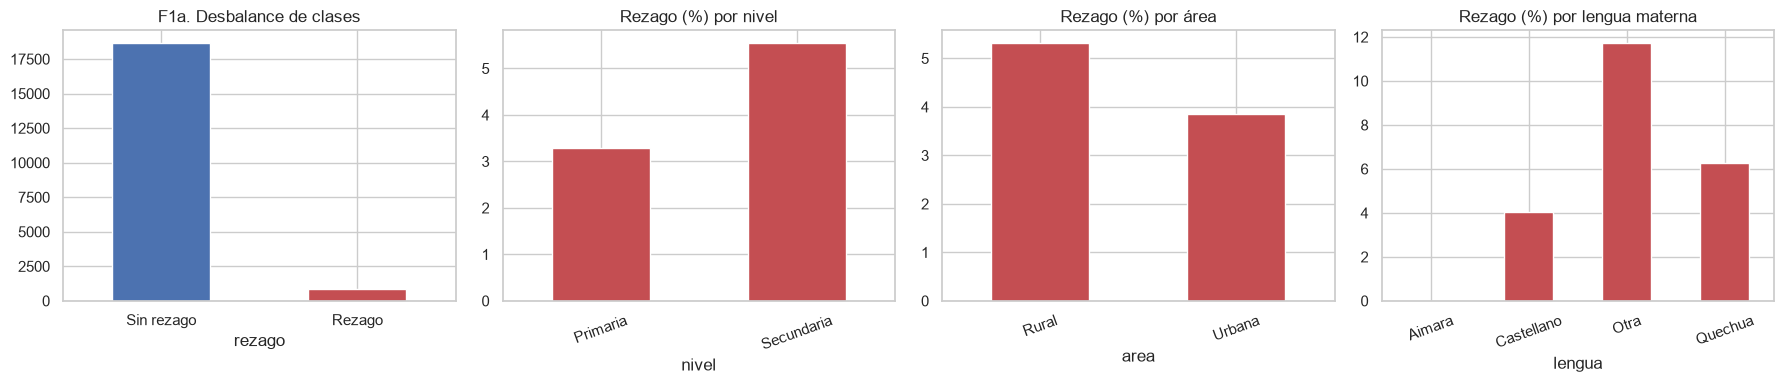

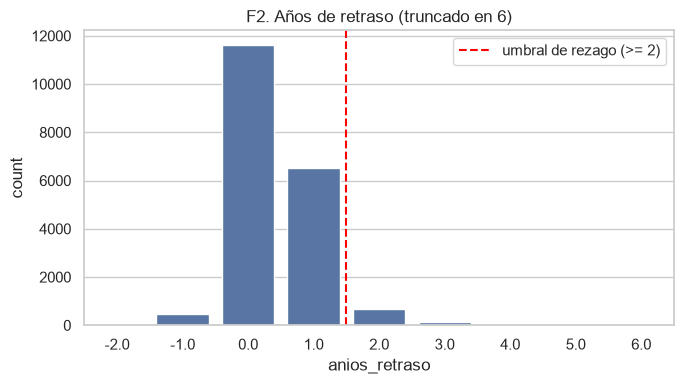

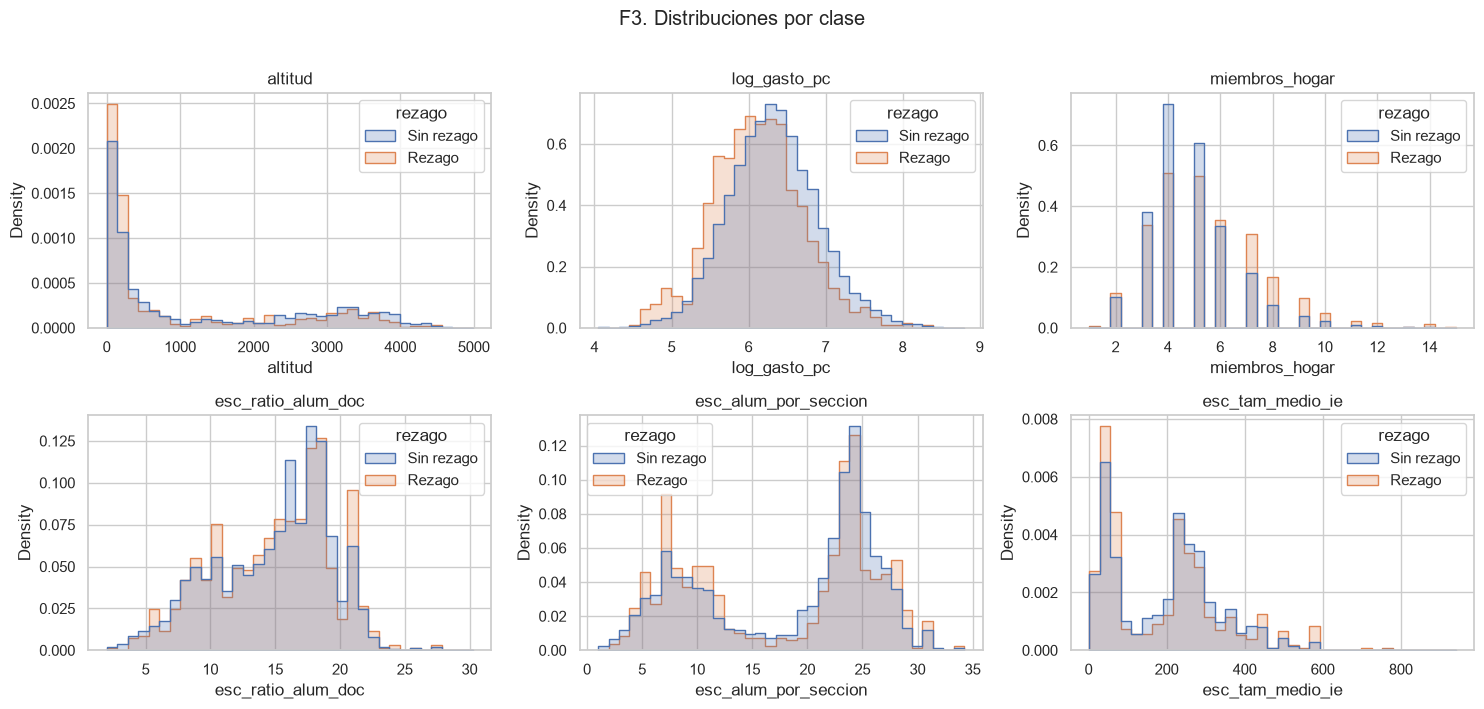

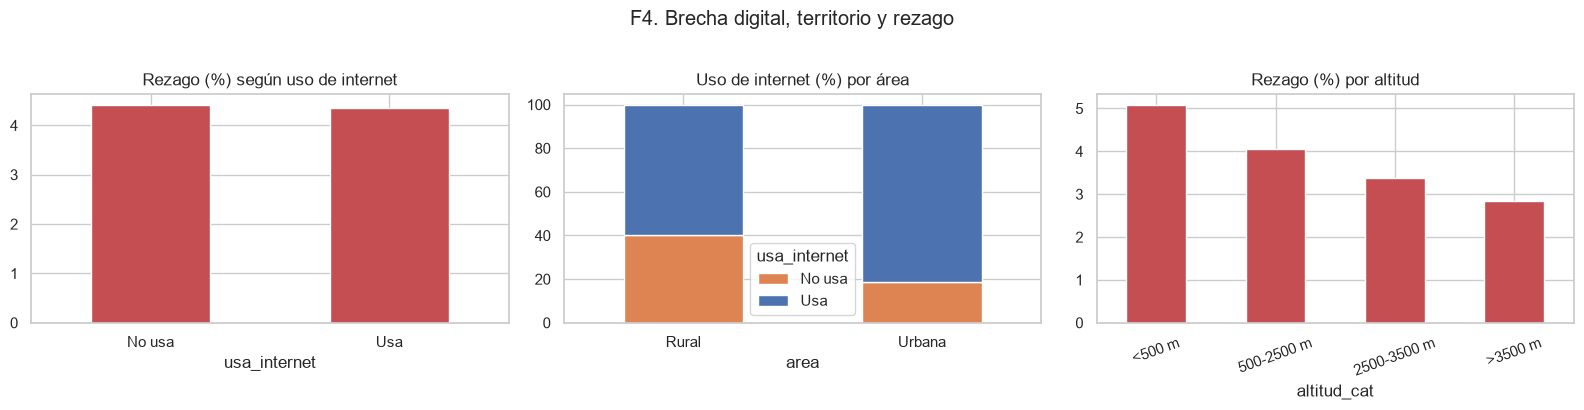

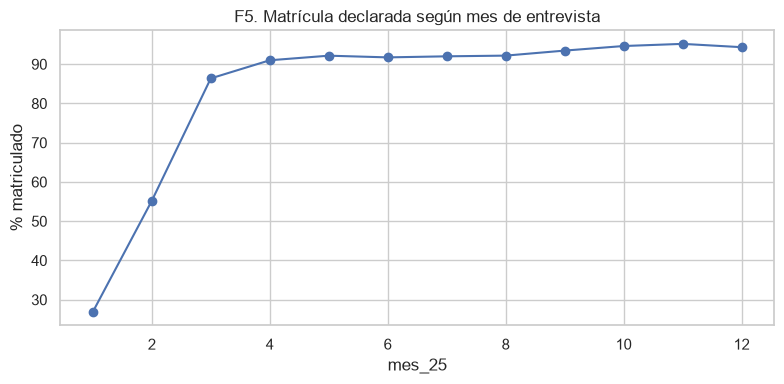

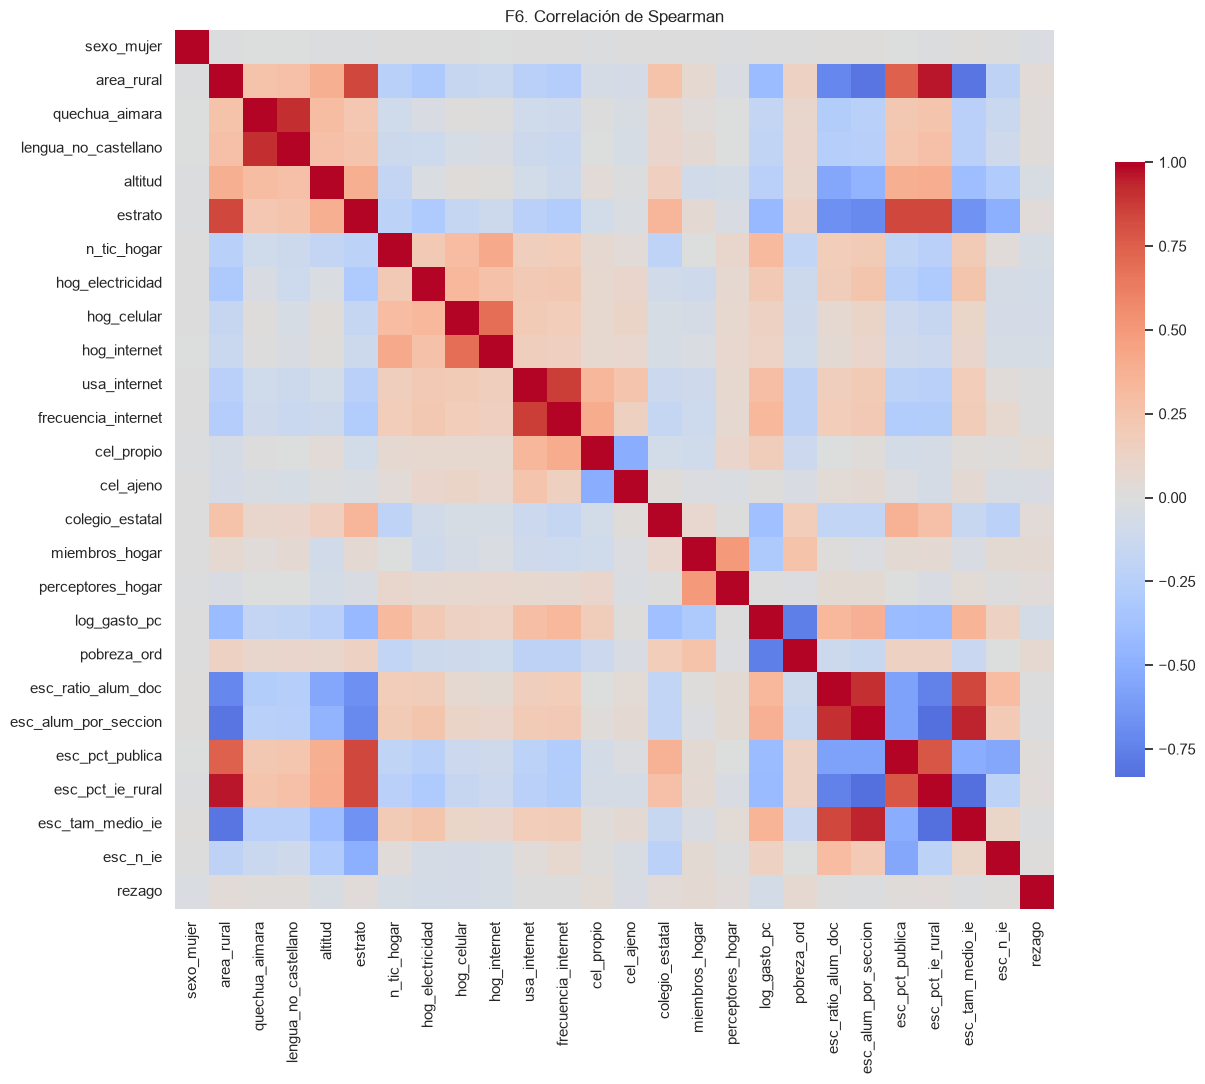


Top correlaciones con rezago:
 hog_electricidad   -0.073
log_gasto_pc       -0.070
hog_celular        -0.066
pobreza_ord         0.066
miembros_hogar      0.056
n_tic_hogar        -0.051
hog_internet       -0.047
cel_propio          0.043
colegio_estatal     0.040
altitud            -0.039
Name: rezago, dtype: float64

Pares con |rho| > 0.8:
 area_rural            esc_pct_ie_rural        0.96
esc_alum_por_seccion  esc_tam_medio_ie        0.94
quechua_aimara        lengua_no_castellano    0.92
esc_ratio_alum_doc    esc_alum_por_seccion    0.91
usa_internet          frecuencia_internet     0.87
area_rural            estrato                 0.84
estrato               esc_pct_publica         0.84
esc_ratio_alum_doc    esc_tam_medio_ie        0.84
estrato               esc_pct_ie_rural        0.84
esc_pct_ie_rural      esc_tam_medio_ie        0.83
esc_alum_por_seccion  esc_pct_ie_rural        0.83
area_rural            esc_tam_medio_ie        0.81
                      esc_alum_por_seccion

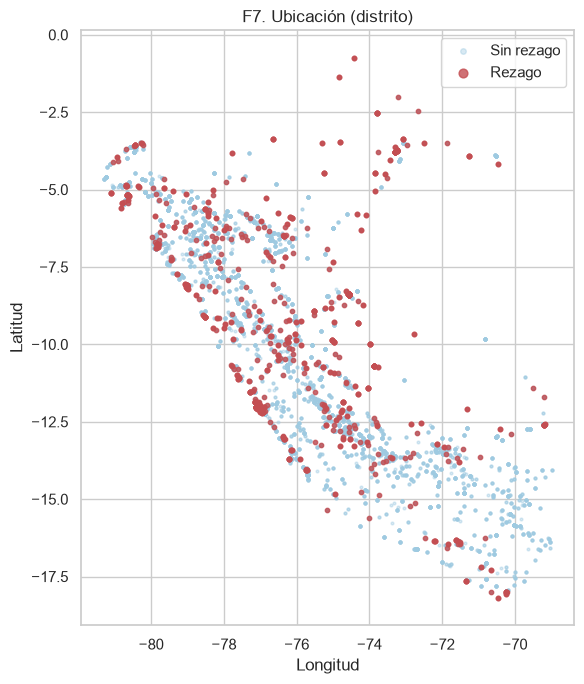


Archivos en C:\IA Unidad II\processed\eda : ['F1_objetivo.png', 'F2_anios_retraso.png', 'F3_distribuciones.png', 'F4_brecha_digital.png', 'F5_calendario.png', 'F6_correlaciones.png', 'F7_mapa.png', 'T0_perfil_crudo.csv', 'T1_embudo.csv', 'T3_tasas_rezago.csv', 'T4_descriptivos.csv']


In [12]:
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style='whitegrid', context='notebook')
EDA = PROC / 'eda'; EDA.mkdir(exist_ok=True)

def guardar(nombre):
    plt.tight_layout(); plt.savefig(EDA / f'{nombre}.png', dpi=150, bbox_inches='tight'); plt.show()

m   = pd.read_parquet(PROC / 'dataset_enaho_escale_2025.parquet')
cfg = json.load(open(PROC / 'config_variables.json'))
v   = m[m['es_valido_obj'] == 1].copy()
v['nivel'] = v['p308a_25'].map({2: 'Primaria', 3: 'Secundaria'})
v['altitud_cat'] = pd.cut(v['altitud'], [-1, 500, 2500, 3500, 6000],
                          labels=['<500 m', '500-2500 m', '2500-3500 m', '>3500 m'])
v['pobreza_txt'] = v['pobreza_ord'].map({0: 'No pobre', 1: 'Pobre no extremo', 2: 'Pobre extremo'})

# ===== E0) EDA en datos CRUDOS =====
raw = pd.read_csv(PROC / 'perfil_raw_enaho.csv')
raw['pct_filas_2025'] = (100 * raw['filas_2025'] / raw['filas_crudas']).round(1)
print("== E0a) Perfil de los CSV crudos (panel 2021-2025) ==\n", raw.to_string(index=False))
raw.to_csv(EDA / 'T0_perfil_crudo.csv', index=False)

pad_raw = pd.read_parquet(PROC / 'padron_basico.parquet')
print("\n== E0b) Padrón ESCALE crudo ==")
print("Filas:", len(pad_raw), "| nulos por columna (%):\n", (pad_raw.isna().mean() * 100).round(2).to_dict())
print("TDOC == 0:", (pad_raw['TDOC'] == 0).sum(), "(todos son programas A5, no escolarizados)")

# ===== T1) Embudo de datos =====
embudo = pd.DataFrame({
  'etapa': ['Hogares Módulo 100 (2025)', 'Hogares Sumaria (2025)', 'Personas Módulo 200 (2025)',
            'Personas Módulo 300 (2025)', 'Estudiantes 6-17 años', 'Con nivel y grado válidos', 'Con rezago (>= 2 años)'],
  'n': [44599, 33702, 115145, 106958, len(m), len(v), int(v['rezago'].sum())]})
print("\n", embudo.to_string(index=False)); embudo.to_csv(EDA / 'T1_embudo.csv', index=False)

# ===== T2) Prevalencia y estructura de grupos =====
prev_s = v['rezago'].mean(); prev_p = np.average(v['rezago'], weights=v['peso_hogar'])
g = v.groupby('conglome_25')['rezago']
print(f"\nPrevalencia simple: {prev_s:.2%} | ponderada (factor07): {prev_p:.2%}")
print(f"Conglomerados: {g.ngroups} | con >=1 rezago: {(g.sum() > 0).sum()} | estudiantes por conglomerado (mediana): {g.size().median():.0f}")

# ===== T3) Tasas de rezago por grupo =====
def tasa(col):
    t = v.groupby(col, observed=True)['rezago'].agg(n='count', casos='sum', tasa='mean')
    t['tasa'] = (t['tasa'] * 100).round(2); return t
v['colegio'] = v['colegio_estatal'].map({1.0: 'Estatal', 0.0: 'No estatal'})
grupos = ['nivel', 'area', 'lengua', 'altitud_cat', 'pobreza_txt', 'usa_internet',
          'frecuencia_internet', 'colegio', 'sexo_mujer', 'parentesco']
tablas = {c: tasa(c) for c in grupos}
for c, t in tablas.items(): print(f"\n--- {c} ---\n{t}")
pd.concat(tablas, names=['variable', 'categoria']).to_csv(EDA / 'T3_tasas_rezago.csv')

# ===== T4) Descriptivos numéricos =====
num = cfg['num']
desc = v[num].describe().T[['count', 'mean', 'std', 'min', '50%', 'max']].round(2)
desc['nulos_%'] = (v[num].isna().mean() * 100).round(2)
print("\n", desc); desc.to_csv(EDA / 'T4_descriptivos.csv')

# ===== F1) Desbalance y rezago por nivel / área / lengua =====
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
v['rezago'].map({0: 'Sin rezago', 1: 'Rezago'}).value_counts().plot.bar(ax=ax[0], color=['#4C72B0', '#C44E52'])
ax[0].set_title('F1a. Desbalance de clases'); ax[0].tick_params(axis='x', rotation=0)
for a, c, t in zip(ax[1:], ['nivel', 'area', 'lengua'], ['por nivel', 'por área', 'por lengua materna']):
    tablas[c]['tasa'].plot.bar(ax=a, color='#C44E52'); a.set_title(f'Rezago (%) {t}'); a.tick_params(axis='x', rotation=20)
guardar('F1_objetivo')

# ===== F2) Años de retraso =====
plt.figure(figsize=(7, 4))
sns.countplot(x=v['anios_retraso'].clip(-2, 6), color='#4C72B0')
plt.axvline(3.5, color='red', ls='--', label='umbral de rezago (>= 2)')
plt.title('F2. Años de retraso (truncado en 6)'); plt.legend(); guardar('F2_anios_retraso')

# ===== F3) Distribuciones por clase =====
cols = ['altitud', 'log_gasto_pc', 'miembros_hogar', 'esc_ratio_alum_doc', 'esc_alum_por_seccion', 'esc_tam_medio_ie']
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
for a, c in zip(ax.ravel(), cols):
    sns.histplot(data=v, x=c, hue=v['rezago'].map({0: 'Sin rezago', 1: 'Rezago'}),
                 stat='density', common_norm=False, bins=35, ax=a, element='step'); a.set_title(c)
fig.suptitle('F3. Distribuciones por clase', y=1.01); guardar('F3_distribuciones')

# ===== F4) Brecha digital, territorio y rezago =====
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
tablas['usa_internet']['tasa'].rename(index={0.0: 'No usa', 1.0: 'Usa'}).plot.bar(ax=ax[0], color='#C44E52')
ax[0].set_title('Rezago (%) según uso de internet'); ax[0].tick_params(axis='x', rotation=0)
(pd.crosstab(v['area'], v['usa_internet'], normalize='index').rename(columns={0.0: 'No usa', 1.0: 'Usa'}) * 100).round(1).plot.bar(
    stacked=True, ax=ax[1], color=['#DD8452', '#4C72B0']); ax[1].set_title('Uso de internet (%) por área'); ax[1].tick_params(axis='x', rotation=0)
tablas['altitud_cat']['tasa'].plot.bar(ax=ax[2], color='#C44E52'); ax[2].set_title('Rezago (%) por altitud'); ax[2].tick_params(axis='x', rotation=20)
fig.suptitle('F4. Brecha digital, territorio y rezago', y=1.02); guardar('F4_brecha_digital')

# ===== F5) Efecto del calendario escolar =====
mat = m.groupby('mes_25')['p306_25'].apply(lambda s: (s == 1).mean() * 100)
plt.figure(figsize=(8, 4)); mat.plot(marker='o', color='#4C72B0')
plt.ylabel('% matriculado'); plt.title('F5. Matrícula declarada según mes de entrevista'); guardar('F5_calendario')

# ===== F6) Correlaciones (Spearman) =====
corr = v[num + ['rezago']].corr(method='spearman')
plt.figure(figsize=(14, 11)); sns.heatmap(corr, cmap='coolwarm', center=0, square=True, cbar_kws={'shrink': .7})
plt.title('F6. Correlación de Spearman'); guardar('F6_correlaciones')
print("\nTop correlaciones con rezago:\n", corr['rezago'].drop('rezago').sort_values(key=abs, ascending=False).head(10).round(3))
alta = corr.abs().where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
print("\nPares con |rho| > 0.8:\n", alta[alta > 0.8].sort_values(ascending=False).round(2))

# ===== F7) Ubicación de los estudiantes =====
plt.figure(figsize=(6, 7))
a0, a1 = v[v.rezago == 0], v[v.rezago == 1]
plt.scatter(a0['esc_lon_ie_med'], a0['esc_lat_ie_med'], s=4, c='#9ecae1', alpha=.4, label='Sin rezago')
plt.scatter(a1['esc_lon_ie_med'], a1['esc_lat_ie_med'], s=10, c='#C44E52', alpha=.8, label='Rezago')
plt.legend(markerscale=2); plt.xlabel('Longitud'); plt.ylabel('Latitud'); plt.title('F7. Ubicación (distrito)')
guardar('F7_mapa')

print("\nArchivos en", EDA, ":", sorted(p.name for p in EDA.iterdir()))

In [13]:
m = pd.read_parquet(PROC / 'dataset_enaho_escale_2025.parquet')

# 1) Variables nuevas
m['otra_lengua'] = m['p300a_25'].isin([3, 6, 7]).astype(int)
m['parentesco']  = m['parentesco'].replace({'Jefe': 'Otro'})

# 2) Lista final de predictores (quita redundantes; ninguna se eligió por su relación con rezago)
num_modelo = ['sexo_mujer','area_rural','quechua_aimara','otra_lengua','altitud','n_tic_hogar',
              'hog_electricidad','hog_internet','frecuencia_internet','cel_propio','colegio_estatal',
              'miembros_hogar','perceptores_hogar','log_gasto_pc','pobreza_ord',
              'esc_ratio_alum_doc','esc_pct_publica','esc_n_ie']
cat_modelo = ['parentesco', 'dominio']
cfg = json.load(open(PROC / 'config_variables.json'))
cfg['num_modelo'], cfg['cat_modelo'] = num_modelo, cat_modelo
cfg['descartadas_por_redundancia'] = ['estrato','esc_pct_ie_rural','esc_alum_por_seccion','esc_tam_medio_ie',
                                      'usa_internet','hog_celular','cel_ajeno','lengua_no_castellano']
json.dump(cfg, open(PROC / 'config_variables.json', 'w'), indent=2)

dic = pd.read_csv(PROC / 'diccionario_variables.csv')
dic.loc[len(dic)] = ['otra_lengua', '1 si lengua materna es otra nativa o extranjera (códigos 3,6,7)', 'p300a']
dic.to_csv(PROC / 'diccionario_variables.csv', index=False, encoding='utf-8-sig')
m.to_parquet(PROC / 'dataset_enaho_escale_2025.parquet', index=False)
m.to_csv(PROC / 'dataset_enaho_escale_2025.csv', index=False, encoding='utf-8-sig')

# 3) ¿El CSV conserva los ceros?
print(pd.read_csv(PROC / 'dataset_enaho_escale_2025.csv', nrows=3, dtype=str,
                  usecols=['conglome_25', 'ubigeo_25']))

# 4) ¿La no-asociación de internet es confusión?
v = m[m['es_valido_obj'] == 1].copy()
v['nivel'] = v['p308a_25'].map({2: 'Primaria', 3: 'Secundaria'})
print("\nEdad media según uso de internet:\n", v.groupby('usa_internet')['edad'].mean().round(2))
print("\nRezago por nivel × uso de internet:\n",
      v.groupby(['nivel', 'usa_internet'])['rezago'].agg(['count', 'mean']).round(3))
print("\nRezago por área × uso de internet:\n",
      v.groupby(['area', 'usa_internet'])['rezago'].agg(['count', 'mean']).round(3))
print("\nPredictores:", len(num_modelo), "num +", len(cat_modelo), "cat")

  conglome_25 ubigeo_25
0      015001    010101
1      015001    010101
2      015001    010101

Edad media según uso de internet:
 usa_internet
0.0     9.54
1.0    12.29
Name: edad, dtype: float64

Rezago por nivel × uso de internet:
                          count   mean
nivel      usa_internet              
Primaria   0.0            4158  0.041
           1.0            5950  0.027
Secundaria 0.0             974  0.057
           1.0            8408  0.055

Rezago por área × uso de internet:
                      count   mean
area   usa_internet              
Rural  0.0            2829  0.050
       1.0            4183  0.055
Urbana 0.0            2303  0.037
       1.0           10175  0.039

Predictores: 18 num + 2 cat


algoritmo  k  silueta  davies_bouldin  calinski_harabasz        bic
   KMeans  2    0.267           1.510           7689.239        NaN
      GMM  2    0.215           1.728           5580.680 343595.940
   KMeans  3    0.216           1.829           5099.419        NaN
      GMM  3    0.133           2.489           3667.570 235436.358
   KMeans  4    0.159           2.158           4260.541        NaN
      GMM  4    0.108           4.860           2482.808 162498.636
   KMeans  5    0.163           1.984           3787.327        NaN
      GMM  5    0.099           2.445           2384.898 136578.105
   KMeans  6    0.167           1.825           3447.885        NaN
      GMM  6    0.128           1.997           2529.772 164231.247
   KMeans  7    0.167           1.728           3262.223        NaN
      GMM  7    0.072           3.397           1745.484  59527.516
   KMeans  8    0.176           1.663           3095.737        NaN
      GMM  8    0.069           2.701           

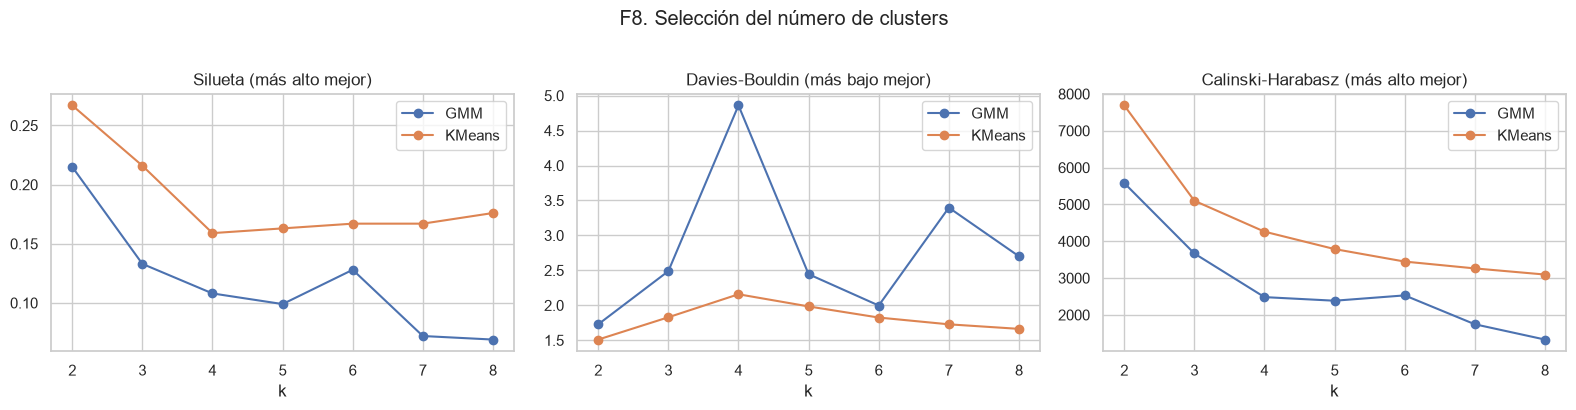

In [14]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
import matplotlib.pyplot as plt

vars_cl = ['log_gasto_pc', 'esc_ratio_alum_doc', 'frecuencia_internet', 'n_tic_hogar',
           'altitud', 'estrato', 'esc_pct_publica', 'miembros_hogar', 'anios_retraso']
Xc = v[vars_cl].copy()
Xc['anios_retraso'] = Xc['anios_retraso'].clip(0, 4)      # trunca valores extremos
Xs = StandardScaler().fit_transform(Xc)

filas = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Xs)
    gm = GaussianMixture(n_components=k, covariance_type='full', n_init=3, random_state=SEED).fit(Xs)
    for nombre, lab in [('KMeans', km.labels_), ('GMM', gm.predict(Xs))]:
        filas.append({'algoritmo': nombre, 'k': k,
                      'silueta': silhouette_score(Xs, lab, sample_size=6000, random_state=SEED),
                      'davies_bouldin': davies_bouldin_score(Xs, lab),
                      'calinski_harabasz': calinski_harabasz_score(Xs, lab),
                      'bic': gm.bic(Xs) if nombre == 'GMM' else np.nan})
res = pd.DataFrame(filas).round(3)
print(res.to_string(index=False))
res.to_csv(EDA / 'T5_metricas_clustering.csv', index=False)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, c, t in zip(ax, ['silueta', 'davies_bouldin', 'calinski_harabasz'],
                   ['Silueta (más alto mejor)', 'Davies-Bouldin (más bajo mejor)', 'Calinski-Harabasz (más alto mejor)']):
    for alg, d in res.groupby('algoritmo'):
        a.plot(d['k'], d[c], marker='o', label=alg)
    a.set_title(t); a.set_xlabel('k'); a.legend()
fig.suptitle('F8. Selección del número de clusters', y=1.02); guardar('F8_seleccion_k')

          algoritmo  k  silueta  davies_bouldin  calinski_harabasz        bic
           GMM-diag  2    0.248           1.589           6828.202 411949.317
           GMM-tied  2    0.261           1.535           7390.687 429680.255
           GMM-diag  3    0.156           2.390           4263.223 361528.156
           GMM-tied  3    0.128           2.670           4271.358 420343.790
           GMM-diag  4    0.158           2.237           3051.892 341734.394
           GMM-tied  4    0.130           2.418           3624.111 417499.110
           GMM-diag  5    0.115           2.437           2717.796 318026.932
           GMM-tied  5    0.159           2.052           3446.216 391225.996
           GMM-diag  6    0.155           1.958           2949.603 309270.935
           GMM-tied  6    0.105           2.448           2862.889 384942.539
           GMM-diag  7    0.107           2.180           2501.721 285600.357
           GMM-tied  7    0.116           2.144           2629.1

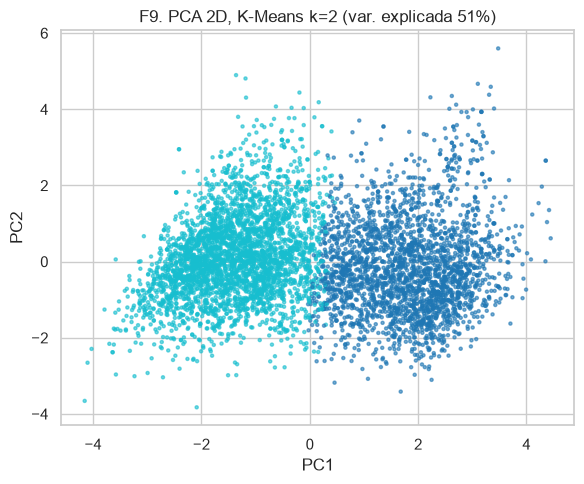


===== K-Means k=3 =====
cluster                    0        1         2
n                    3666.00  5168.00  10656.00
pct                    18.80    26.50     54.70
log_gasto_pc            5.86     6.11      6.56
esc_ratio_alum_doc     11.80    10.90     17.90
frecuencia_internet     0.04     3.71      3.29
n_tic_hogar             1.88     2.14      2.37
altitud              1806.55  2105.89    652.65
estrato                 6.57     6.59      2.49
esc_pct_publica         0.95     0.96      0.46
miembros_hogar          5.23     4.69      4.76
anios_retraso           0.43     0.47      0.41
area_rural              0.78     0.79      0.01
usa_internet            0.02     1.00      0.86
quechua_aimara          0.13     0.10      0.01
colegio_estatal         0.98     0.97      0.75
sexo_mujer              0.48     0.48      0.50
rezago_%                4.94     5.01      3.87
ARI contra area_rural: 0.58


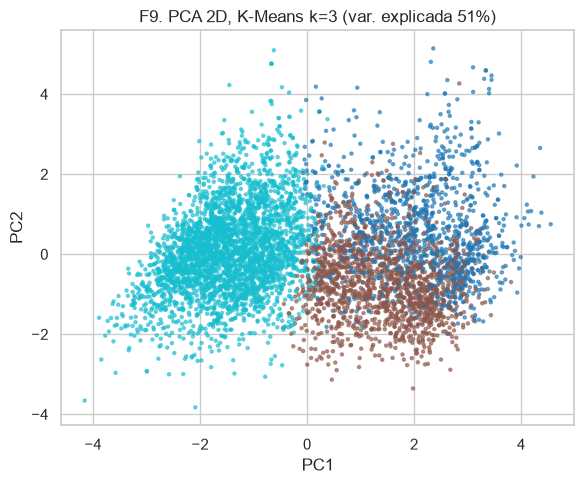


===== K-Means k=4 =====
cluster                    0        1        2        3
n                    4997.00  6543.00  3413.00  4537.00
pct                    25.60    33.60    17.50    23.30
log_gasto_pc            6.11     6.82     5.86     6.13
esc_ratio_alum_doc     10.75    17.55    11.31    18.33
frecuencia_internet     3.71     3.63     0.04     2.63
n_tic_hogar             2.14     2.48     1.86     2.19
altitud              2144.27   773.21  1885.14   496.52
estrato                 6.62     2.45     6.78     2.73
esc_pct_publica         0.96     0.44     0.97     0.51
miembros_hogar          4.64     3.97     5.15     6.04
anios_retraso           0.46     0.33     0.42     0.55
area_rural              0.80     0.01     0.84     0.01
usa_internet            1.00     0.94     0.02     0.70
quechua_aimara          0.11     0.01     0.14     0.01
colegio_estatal         0.97     0.68     0.98     0.89
sexo_mujer              0.48     0.49     0.48     0.50
rezago_%               

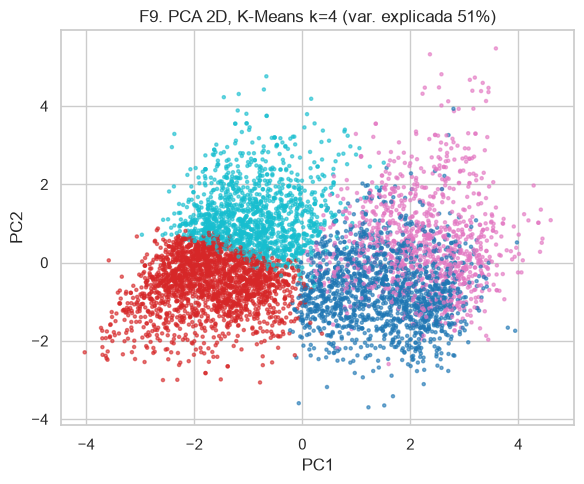

In [15]:
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score

# ---------- 1) GMM alternativo (diag / tied, con regularización) ----------
filas = []
for k in range(2, 9):
    for cov in ['diag', 'tied']:
        gm = GaussianMixture(n_components=k, covariance_type=cov, reg_covar=1e-3,
                             n_init=3, random_state=SEED).fit(Xs)
        lab = gm.predict(Xs)
        filas.append({'algoritmo': f'GMM-{cov}', 'k': k,
                      'silueta': silhouette_score(Xs, lab, sample_size=6000, random_state=SEED),
                      'davies_bouldin': davies_bouldin_score(Xs, lab),
                      'calinski_harabasz': calinski_harabasz_score(Xs, lab), 'bic': gm.bic(Xs)})

# ---------- 2) Jerárquico (Ward) sobre muestra de 5000 por memoria ----------
rng = np.random.RandomState(SEED)
idx = rng.choice(len(Xs), 5000, replace=False)
for k in range(2, 9):
    lab = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(Xs[idx])
    filas.append({'algoritmo': 'Ward (muestra 5000)', 'k': k,
                  'silueta': silhouette_score(Xs[idx], lab),
                  'davies_bouldin': davies_bouldin_score(Xs[idx], lab),
                  'calinski_harabasz': calinski_harabasz_score(Xs[idx], lab), 'bic': np.nan})
res2 = pd.DataFrame(filas).round(3)
print(res2.to_string(index=False))
res2.to_csv(EDA / 'T6_clustering_alternativos.csv', index=False)

# ---------- 3) Perfiles de los clusters K-Means para k = 2, 3 y 4 ----------
tmp = v.copy()
tmp['anios_retraso'] = Xc['anios_retraso']
extras = ['area_rural', 'usa_internet', 'quechua_aimara', 'colegio_estatal', 'sexo_mujer']

def perfilar(K):
    km = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(Xs)
    tmp['cluster'] = km.labels_
    p = tmp.groupby('cluster')[vars_cl + extras].mean()
    p.insert(0, 'n', tmp.groupby('cluster').size())
    p.insert(1, 'pct', (100 * p['n'] / len(tmp)).round(1))
    p['rezago_%'] = (100 * tmp.groupby('cluster')['rezago'].mean()).round(2)
    print(f"\n===== K-Means k={K} =====")
    print(p.round(2).T.to_string())
    print("ARI contra area_rural:", round(adjusted_rand_score(tmp['area_rural'], km.labels_), 3))
    p.round(3).to_csv(EDA / f'T7_perfil_kmeans_k{K}.csv')

    pc = PCA(n_components=2, random_state=SEED).fit(Xs)
    Z = pc.transform(Xs); s = rng.choice(len(Z), 6000, replace=False)
    plt.figure(figsize=(6, 5))
    plt.scatter(Z[s, 0], Z[s, 1], c=km.labels_[s], cmap='tab10', s=5, alpha=.6)
    plt.title(f'F9. PCA 2D, K-Means k={K} (var. explicada {pc.explained_variance_ratio_.sum():.0%})')
    plt.xlabel('PC1'); plt.ylabel('PC2'); guardar(f'F9_pca_k{K}')

for K in (2, 3, 4):
    perfilar(K)

perfil               Rural conectado  Rural sin uso de internet  Urbano conectado
n                            5168.00                    3666.00          10656.00
pct                            26.50                      18.80             54.70
log_gasto_pc                    6.11                       5.86              6.56
esc_ratio_alum_doc             10.90                      11.80             17.90
frecuencia_internet             3.71                       0.04              3.29
n_tic_hogar                     2.14                       1.88              2.37
altitud                      2105.89                    1806.55            652.65
estrato                         6.59                       6.57              2.49
esc_pct_publica                 0.96                       0.95              0.46
miembros_hogar                  4.69                       5.23              4.76
anios_retraso                   0.46                       0.41              0.39
edad            

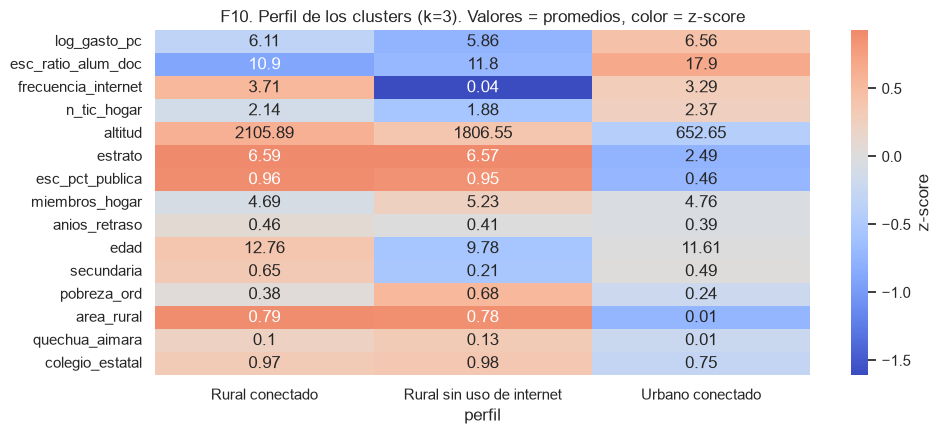


ARI K-Means vs GMM-diag (todos)   : 0.452
ARI K-Means vs Ward (muestra 5000): 0.757


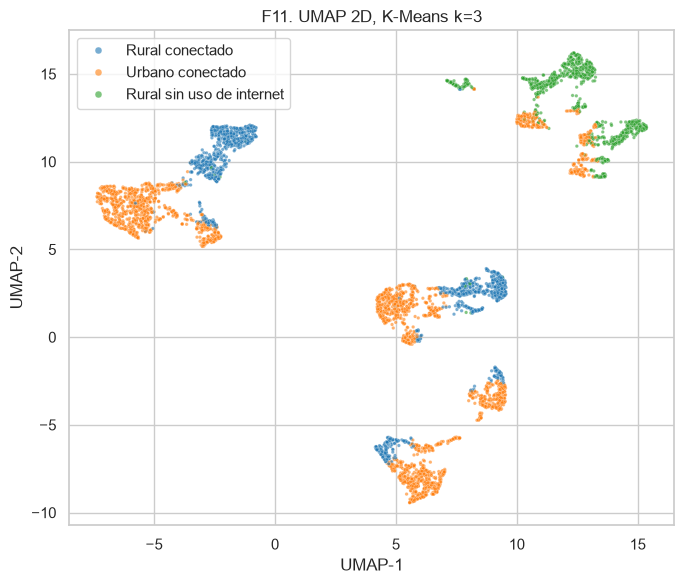


k=4: rezago por cluster
        n  casos  tasa_%  IC95_±
c4                             
0   4997  236.0    4.72    0.59
1   6543  118.0    1.80    0.32
2   3413  162.0    4.75    0.71
3   4537  336.0    7.41    0.76

Guardado clusters_k3_k4.parquet (no usar como predictor)


In [16]:
from pathlib import Path
import pandas as pd, numpy as np, json
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score
import umap

SEED = 42
PROC = Path('.').resolve() / 'processed'; EDA = PROC / 'eda'; EDA.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid')
def guardar(nombre):
    plt.tight_layout(); plt.savefig(EDA / f'{nombre}.png', dpi=150, bbox_inches='tight'); plt.show()

m = pd.read_parquet(PROC / 'dataset_enaho_escale_2025.parquet')
v = m[m['es_valido_obj'] == 1].copy().reset_index(drop=True)
vars_cl = ['log_gasto_pc', 'esc_ratio_alum_doc', 'frecuencia_internet', 'n_tic_hogar',
           'altitud', 'estrato', 'esc_pct_publica', 'miembros_hogar', 'anios_retraso']
Xc = v[vars_cl].copy(); Xc['anios_retraso'] = Xc['anios_retraso'].clip(0, 4)
Xs = StandardScaler().fit_transform(Xc)

# ---------- 1) K-Means k=3 y nombres asignados por reglas (no por número de etiqueta) ----------
km3 = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(Xs)
v['cluster'] = km3.labels_
med = v.groupby('cluster')[['area_rural', 'usa_internet']].mean()
urb = med['area_rural'].idxmin()
sin_int = med.drop(urb)['usa_internet'].idxmin()
rur_con = [c for c in med.index if c not in (urb, sin_int)][0]
v['perfil'] = v['cluster'].map({urb: 'Urbano conectado', rur_con: 'Rural conectado',
                                sin_int: 'Rural sin uso de internet'})

# ---------- 2) Perfil con variables extra (NO usadas en el clustering) ----------
v['secundaria'] = (v['p308a_25'] == 3).astype(int)
extras = ['edad', 'secundaria', 'pobreza_ord', 'area_rural', 'quechua_aimara', 'colegio_estatal']
perfil = v.groupby('perfil')[vars_cl + extras].mean()
n = v.groupby('perfil').size(); p = v.groupby('perfil')['rezago'].mean()
perfil.insert(0, 'n', n); perfil.insert(1, 'pct', (100 * n / len(v)).round(1))
perfil['casos_rezago'] = v.groupby('perfil')['rezago'].sum().astype(int)
perfil['rezago_%'] = (100 * p).round(2)
perfil['IC95_±'] = (196 * np.sqrt(p * (1 - p) / n)).round(2)
print(perfil.round(2).T.to_string()); perfil.round(3).to_csv(EDA / 'T8_perfil_k3_final.csv')

# F10: mapa de calor de los perfiles (promedios estandarizados)
cols = vars_cl + extras
z = (perfil[cols] - v[cols].mean()) / v[cols].std()
plt.figure(figsize=(10, 4.5))
sns.heatmap(z.T, annot=perfil[cols].T.round(2), fmt='', cmap='coolwarm', center=0, cbar_kws={'label': 'z-score'})
plt.title('F10. Perfil de los clusters (k=3). Valores = promedios, color = z-score'); plt.ylabel('')
guardar('F10_perfil_heatmap')

# ---------- 3) Estabilidad entre algoritmos (k=3) ----------
gm3 = GaussianMixture(3, covariance_type='diag', reg_covar=1e-3, n_init=3, random_state=SEED).fit(Xs)
rng = np.random.RandomState(SEED); idx = rng.choice(len(Xs), 5000, replace=False)
w3 = AgglomerativeClustering(n_clusters=3, linkage='ward').fit_predict(Xs[idx])
print("\nARI K-Means vs GMM-diag (todos)   :", round(adjusted_rand_score(km3.labels_, gm3.predict(Xs)), 3))
print("ARI K-Means vs Ward (muestra 5000):", round(adjusted_rand_score(km3.labels_[idx], w3), 3))

# ---------- 4) UMAP 2D (muestra de 6000) ----------
s = rng.choice(len(Xs), 6000, replace=False)
emb = umap.UMAP(n_neighbors=30, min_dist=0.1, random_state=SEED).fit_transform(Xs[s])
plt.figure(figsize=(7, 6))
sns.scatterplot(x=emb[:, 0], y=emb[:, 1], hue=v['perfil'].iloc[s].values, s=6, alpha=.6, palette='tab10')
plt.title('F11. UMAP 2D, K-Means k=3'); plt.xlabel('UMAP-1'); plt.ylabel('UMAP-2'); plt.legend(markerscale=2)
guardar('F11_umap_k3')

# ---------- 5) Refinamiento k=4: ¿qué tan sólida es la diferencia de rezago? ----------
v['c4'] = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit_predict(Xs)
t4 = v.groupby('c4')['rezago'].agg(n='count', casos='sum', tasa='mean')
t4['tasa_%'] = (100 * t4['tasa']).round(2)
t4['IC95_±'] = (196 * np.sqrt(t4['tasa'] * (1 - t4['tasa']) / t4['n'])).round(2)
print("\nk=4: rezago por cluster\n", t4.drop(columns='tasa'))

# ---------- 6) Guardar etiquetas APARTE (no se mezclan con el dataset de modelado) ----------
v[['numper', 'conglome_25', 'cluster', 'perfil', 'c4']].to_parquet(PROC / 'clusters_k3_k4.parquet', index=False)
print("\nGuardado clusters_k3_k4.parquet (no usar como predictor)")

In [17]:
from pathlib import Path
import pandas as pd, numpy as np, json, warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score
from sklearn.base import clone
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

SEED = 42
PROC = Path('.').resolve() / 'processed'; EDA = PROC / 'eda'

m   = pd.read_parquet(PROC / 'dataset_enaho_escale_2025.parquet')
cfg = json.load(open(PROC / 'config_variables.json'))
num, cat = cfg['num_modelo'], cfg['cat_modelo']

# --- Verificación anti-fuga (Regla 3) ---
prohibidas = set(cfg['excluidos']) | {'cluster', 'perfil', 'c4', 'edad', 'grado', 'anios_retraso'}
assert not (set(num + cat) & prohibidas), "Hay variables prohibidas entre los predictores"

v = m[m['es_valido_obj'] == 1].reset_index(drop=True)
X = v[num + cat].copy(); X[cat] = X[cat].astype(str)
y = v['rezago'].astype(int); g = v['conglome_25']

# --- Partición train/test por conglomerado (Regla 1) ---
tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(X, y, g))
assert set(g.iloc[tr]).isdisjoint(set(g.iloc[te])), "Conglomerados compartidos entre train y test"
Xtr, ytr, gtr = X.iloc[tr].reset_index(drop=True), y.iloc[tr].reset_index(drop=True), g.iloc[tr].reset_index(drop=True)
Xte, yte = X.iloc[te].reset_index(drop=True), y.iloc[te].reset_index(drop=True)
v.assign(split=np.where(v.index.isin(tr), 'train', 'test'))[['numper', 'conglome_25', 'split']] \
 .to_parquet(PROC / 'split_train_test.parquet', index=False)

print(f"Train: {len(Xtr):,} ({ytr.sum()} rezago, {ytr.mean():.2%}) | Test: {len(Xte):,} ({yte.sum()} rezago, {yte.mean():.2%})")
print(f"Conglomerados train: {gtr.nunique():,} | test: {g.iloc[te].nunique():,}")
spw = (ytr == 0).sum() / (ytr == 1).sum()
print(f"scale_pos_weight (solo con train): {spw:.1f} | PR-AUC de un modelo al azar = {ytr.mean():.3f}")

# --- Preprocesamiento (se ajusta dentro de cada fold) ---
def prep(escalar):
    pasos = [('imp', SimpleImputer(strategy='median'))] + ([('sc', StandardScaler())] if escalar else [])
    return ColumnTransformer([
        ('num', Pipeline(pasos), num),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                          ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat)])

modelos = {
 'Baseline: Reg. logística': Pipeline([('prep', prep(True)), ('clf', LogisticRegression(
        C=0.1, class_weight='balanced', max_iter=2000, random_state=SEED))]),
 'Random Forest': Pipeline([('prep', prep(False)), ('clf', RandomForestClassifier(
        n_estimators=500, min_samples_leaf=20, max_features='sqrt',
        class_weight='balanced_subsample', n_jobs=-1, random_state=SEED))]),
 'LightGBM': Pipeline([('prep', prep(False)), ('clf', LGBMClassifier(
        n_estimators=300, learning_rate=0.03, num_leaves=15, min_child_samples=50,
        subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=5,
        scale_pos_weight=spw, random_state=SEED, n_jobs=-1, verbose=-1))]),
 'XGBoost': Pipeline([('prep', prep(False)), ('clf', XGBClassifier(
        n_estimators=300, learning_rate=0.03, max_depth=3, min_child_weight=5,
        subsample=0.8, colsample_bytree=0.8, reg_lambda=5, scale_pos_weight=spw,
        eval_metric='aucpr', tree_method='hist', random_state=SEED, n_jobs=-1))]),
}

# --- Validación cruzada agrupada (solo sobre train) ---
def mejor_umbral(y_true, p):
    ths = np.unique(np.quantile(p, np.linspace(0.50, 0.995, 120)))
    f1s = [f1_score(y_true, (p >= t).astype(int), average='macro') for t in ths]
    return ths[int(np.argmax(f1s))], max(f1s)

gkf = GroupKFold(n_splits=5)
filas, oof_all = [], {}
for nombre, pipe in modelos.items():
    oof = np.zeros(len(Xtr)); rocs, aps = [], []
    for a, b in gkf.split(Xtr, ytr, gtr):
        mod = clone(pipe).fit(Xtr.iloc[a], ytr.iloc[a])
        p = mod.predict_proba(Xtr.iloc[b])[:, 1]; oof[b] = p
        rocs.append(roc_auc_score(ytr.iloc[b], p)); aps.append(average_precision_score(ytr.iloc[b], p))
    th, f1m = mejor_umbral(ytr, oof)
    oof_all[nombre] = oof
    filas.append({'modelo': nombre, 'ROC-AUC': f"{np.mean(rocs):.3f} ± {np.std(rocs):.3f}",
                  'PR-AUC': f"{np.mean(aps):.3f} ± {np.std(aps):.3f}",
                  'F1 macro (umbral OOF)': round(f1m, 3), 'umbral': round(th, 3)})
    print(f"{nombre:26s} ROC {np.mean(rocs):.3f} | PR {np.mean(aps):.3f} | F1m {f1m:.3f}")

res = pd.DataFrame(filas)
print("\n", res.to_string(index=False))
res.to_csv(EDA / 'T9_cv_modelos.csv', index=False)
pd.DataFrame(oof_all).assign(y=ytr.values, grupo=gtr.values).to_parquet(PROC / 'oof_train.parquet', index=False)

Train: 15,610 (701 rezago, 4.49%) | Test: 3,880 (151 rezago, 3.89%)
Conglomerados train: 3,766 | test: 942
scale_pos_weight (solo con train): 21.3 | PR-AUC de un modelo al azar = 0.045
Baseline: Reg. logística   ROC 0.694 | PR 0.101 | F1m 0.559
Random Forest              ROC 0.679 | PR 0.098 | F1m 0.550
LightGBM                   ROC 0.673 | PR 0.094 | F1m 0.551
XGBoost                    ROC 0.684 | PR 0.099 | F1m 0.558

                   modelo       ROC-AUC        PR-AUC  F1 macro (umbral OOF)  umbral
Baseline: Reg. logística 0.694 ± 0.014 0.101 ± 0.016                  0.559   0.699
           Random Forest 0.679 ± 0.018 0.098 ± 0.012                  0.550   0.546
                LightGBM 0.673 ± 0.016 0.094 ± 0.007                  0.551   0.684
                 XGBoost 0.684 ± 0.013 0.099 ± 0.009                  0.558   0.678


In [18]:
from pathlib import Path
import pandas as pd, numpy as np, json, warnings, joblib
warnings.filterwarnings('ignore')
from scipy.stats import randint, uniform, loguniform
from sklearn.model_selection import GroupKFold, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

SEED = 42
PROC = Path('.').resolve() / 'processed'; EDA = PROC / 'eda'

m   = pd.read_parquet(PROC / 'dataset_enaho_escale_2025.parquet')
cfg = json.load(open(PROC / 'config_variables.json'))
num, cat = cfg['num_modelo'], cfg['cat_modelo']
sp  = pd.read_parquet(PROC / 'split_train_test.parquet')

v = m[m['es_valido_obj'] == 1].reset_index(drop=True)
assert (v['numper'].values == sp['numper'].values).all(), "El orden no coincide con el split guardado"
X = v[num + cat].copy(); X[cat] = X[cat].astype(str)
y = v['rezago'].astype(int); g = v['conglome_25']
tr = np.where(sp['split'] == 'train')[0]
Xtr, ytr, gtr = X.iloc[tr].reset_index(drop=True), y.iloc[tr].reset_index(drop=True), g.iloc[tr].reset_index(drop=True)
spw = (ytr == 0).sum() / (ytr == 1).sum()

def prep():
    return ColumnTransformer([
        ('num', SimpleImputer(strategy='median'), num),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                          ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat)])

espacios = {
 'XGBoost': (XGBClassifier(eval_metric='aucpr', tree_method='hist', scale_pos_weight=spw,
                           random_state=SEED, n_jobs=-1),
   {'n_estimators': randint(100, 500), 'learning_rate': loguniform(0.01, 0.1),
    'max_depth': randint(2, 5), 'min_child_weight': randint(3, 30),
    'subsample': uniform(0.6, 0.4), 'colsample_bytree': uniform(0.5, 0.5),
    'reg_lambda': loguniform(1, 50), 'gamma': uniform(0, 2)}),
 'LightGBM': (LGBMClassifier(scale_pos_weight=spw, subsample_freq=1, random_state=SEED, n_jobs=-1, verbose=-1),
   {'n_estimators': randint(100, 500), 'learning_rate': loguniform(0.01, 0.1),
    'num_leaves': randint(4, 24), 'min_child_samples': randint(30, 150),
    'subsample': uniform(0.6, 0.4), 'colsample_bytree': uniform(0.5, 0.5),
    'reg_lambda': loguniform(1, 50)}),
 'Random Forest': (RandomForestClassifier(class_weight='balanced_subsample', random_state=SEED, n_jobs=-1),
   {'n_estimators': randint(200, 600), 'min_samples_leaf': randint(10, 80),
    'max_features': uniform(0.2, 0.5), 'max_depth': randint(4, 14)}),
}

gkf = GroupKFold(n_splits=5)
filas, mejores = [], {}
for nombre, (est, dist) in espacios.items():
    pipe = Pipeline([('prep', prep()), ('clf', est)])
    busq = RandomizedSearchCV(pipe, {f'clf__{k}': d for k, d in dist.items()}, n_iter=25,
                              scoring='average_precision', cv=gkf, random_state=SEED,
                              n_jobs=1, refit=True, verbose=0)
    busq.fit(Xtr, ytr, groups=gtr)
    mejores[nombre] = busq.best_estimator_
    filas.append({'modelo': nombre, 'PR-AUC CV (mejor)': round(busq.best_score_, 4),
                  'params': {k.replace('clf__', ''): (round(v_, 4) if isinstance(v_, float) else v_)
                             for k, v_ in busq.best_params_.items()}})
    print(f"{nombre:14s} PR-AUC CV = {busq.best_score_:.4f}\n   {filas[-1]['params']}")

res = pd.DataFrame(filas)
res.to_csv(EDA / 'T10_hiperparametros.csv', index=False)
joblib.dump(mejores, PROC / 'modelos_ajustados.joblib')
print("\nGuardado modelos_ajustados.joblib")

XGBoost        PR-AUC CV = 0.1029
   {'colsample_bytree': np.float64(0.6555), 'gamma': np.float64(0.6504), 'learning_rate': np.float64(0.0537), 'max_depth': 3, 'min_child_weight': 29, 'n_estimators': 134, 'reg_lambda': np.float64(6.3428), 'subsample': np.float64(0.6478)}
LightGBM       PR-AUC CV = 0.1013
   {'colsample_bytree': np.float64(0.9436), 'learning_rate': np.float64(0.0297), 'min_child_samples': 130, 'n_estimators': 230, 'num_leaves': 4, 'reg_lambda': np.float64(16.8344), 'subsample': np.float64(0.6944)}
Random Forest  PR-AUC CV = 0.0982
   {'max_depth': 13, 'max_features': np.float64(0.2233), 'min_samples_leaf': 69, 'n_estimators': 470}

Guardado modelos_ajustados.joblib


Test: 3,880 estudiantes, 151 con rezago (3.89%) | 942 conglomerados
                  modelo  umbral (OOF)             ROC-AUC              PR-AUC            F1 macro           Precisión              Recall
Baseline: Reg. logística         0.696 0.686 [0.632-0.735] 0.100 [0.071-0.135] 0.547 [0.523-0.570] 0.109 [0.072-0.145] 0.238 [0.155-0.324]
                 XGBoost         0.685 0.693 [0.643-0.739] 0.102 [0.071-0.139] 0.553 [0.525-0.577] 0.125 [0.078-0.165] 0.185 [0.106-0.261]
                LightGBM         0.657 0.687 [0.636-0.732] 0.106 [0.072-0.144] 0.561 [0.535-0.581] 0.129 [0.090-0.161] 0.265 [0.177-0.344]
           Random Forest         0.588 0.678 [0.623-0.725] 0.100 [0.072-0.142] 0.552 [0.524-0.578] 0.117 [0.074-0.158] 0.232 [0.141-0.323]


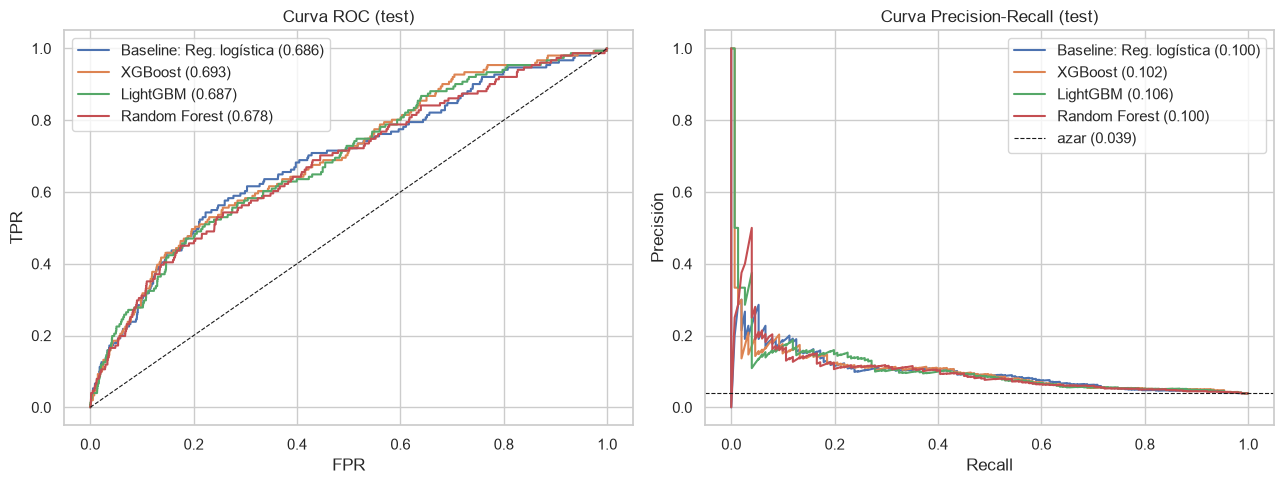


XGBoost | umbral 0.685
TN=3533 FP=196 FN=123 TP=28
Marcados como riesgo: 224 (5.8%) | precisión 0.125 | recall 0.185
Brier crudo: 0.1946 | recalibrado: 0.0365 | referencia (prevalencia constante): 0.0374


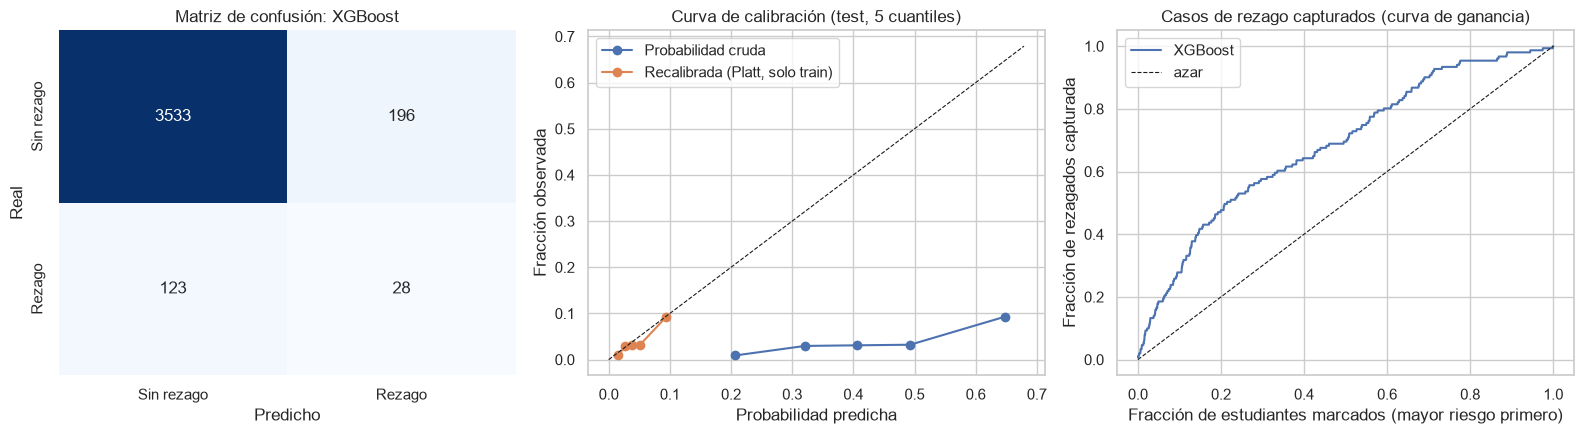

Top 10% de riesgo: captura 27.8% de los casos | precisión 0.108 | lift 2.78x
Top 20% de riesgo: captura 47.7% de los casos | precisión 0.093 | lift 2.38x
Top 30% de riesgo: captura 57.6% de los casos | precisión 0.075 | lift 1.92x

Perfil de aciertos y errores (medias):
 grupo                    TP      FP      FN       TN
edad                  13.57   12.48   13.93    11.46
secundaria             0.50    0.61    0.62     0.48
area_rural             0.75    0.60    0.29     0.32
pobreza_ord            1.04    1.04    0.38     0.31
quechua_aimara         0.11    0.08    0.05     0.06
otra_lengua            0.14    0.10    0.02     0.01
colegio_estatal        0.96    0.97    0.93     0.84
log_gasto_pc           5.61    5.67    6.27     6.37
miembros_hogar         7.00    6.94    5.08     4.68
frecuencia_internet    1.96    2.34    2.76     2.82
altitud              644.32  744.86  901.97  1260.53
sexo_mujer             0.29    0.33    0.45     0.50
n                     28.00  196.00  12

In [19]:
from pathlib import Path
import pandas as pd, numpy as np, json, warnings, joblib
warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import GroupKFold
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import calibration_curve
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, confusion_matrix,
                             roc_curve, precision_recall_curve, precision_score, recall_score,
                             brier_score_loss)

SEED = 42
PROC = Path('.').resolve() / 'processed'; EDA = PROC / 'eda'
sns.set_theme(style='whitegrid')
def guardar(nombre):
    plt.tight_layout(); plt.savefig(EDA / f'{nombre}.png', dpi=150, bbox_inches='tight'); plt.show()

# ---------- Datos y split guardado ----------
m   = pd.read_parquet(PROC / 'dataset_enaho_escale_2025.parquet')
cfg = json.load(open(PROC / 'config_variables.json'))
num, cat = cfg['num_modelo'], cfg['cat_modelo']
sp  = pd.read_parquet(PROC / 'split_train_test.parquet')
v   = m[m['es_valido_obj'] == 1].reset_index(drop=True)
assert (v['numper'].values == sp['numper'].values).all()
X = v[num + cat].copy(); X[cat] = X[cat].astype(str)
y = v['rezago'].astype(int); g = v['conglome_25']
tr, te = np.where(sp['split'] == 'train')[0], np.where(sp['split'] == 'test')[0]
Xtr, ytr, gtr = X.iloc[tr].reset_index(drop=True), y.iloc[tr].reset_index(drop=True), g.iloc[tr].reset_index(drop=True)
Xte, yte, gte = X.iloc[te].reset_index(drop=True), y.iloc[te].reset_index(drop=True), g.iloc[te].reset_index(drop=True)
vte = v.iloc[te].reset_index(drop=True)
assert set(gtr).isdisjoint(set(gte))

# ---------- Modelos: baseline + 3 ajustados ----------
mejores = joblib.load(PROC / 'modelos_ajustados.joblib')
base = Pipeline([('prep', ColumnTransformer([
          ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num),
          ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                            ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat)])),
         ('clf', LogisticRegression(C=0.1, class_weight='balanced', max_iter=2000, random_state=SEED))])
modelos = {'Baseline: Reg. logística': base, 'XGBoost': mejores['XGBoost'],
           'LightGBM': mejores['LightGBM'], 'Random Forest': mejores['Random Forest']}
GANADOR = 'XGBoost'          # decidido por PR-AUC de CV (7B), antes de ver el test

def mejor_umbral(yt, p):
    ths = np.unique(np.quantile(p, np.linspace(0.50, 0.995, 150)))
    f1s = [f1_score(yt, (p >= t).astype(int), average='macro') for t in ths]
    return ths[int(np.argmax(f1s))]

# ---------- OOF en train (umbral y recalibración) + ajuste final + predicción en test ----------
gkf = GroupKFold(n_splits=5)
oof, p_te, umbral, fitted = {}, {}, {}, {}
for nombre, pipe in modelos.items():
    o = np.zeros(len(Xtr))
    for a, b in gkf.split(Xtr, ytr, gtr):
        o[b] = clone(pipe).fit(Xtr.iloc[a], ytr.iloc[a]).predict_proba(Xtr.iloc[b])[:, 1]
    oof[nombre] = o; umbral[nombre] = mejor_umbral(ytr, o)
    fitted[nombre] = clone(pipe).fit(Xtr, ytr)
    p_te[nombre] = fitted[nombre].predict_proba(Xte)[:, 1]

# ---------- Bootstrap por conglomerado (1000 réplicas) ----------
rng = np.random.RandomState(SEED)
idx_g = {k: np.array(ix) for k, ix in gte.groupby(gte).groups.items()}
claves = np.array(list(idx_g.keys()))
muestras = [np.concatenate([idx_g[k] for k in rng.choice(claves, len(claves), replace=True)]) for _ in range(1000)]

def metricas(yt, p, th):
    pred = (p >= th).astype(int)
    return {'ROC-AUC': roc_auc_score(yt, p), 'PR-AUC': average_precision_score(yt, p),
            'F1 macro': f1_score(yt, pred, average='macro'),
            'Precisión': precision_score(yt, pred, zero_division=0), 'Recall': recall_score(yt, pred)}

filas = []
for nombre in modelos:
    pt, th = p_te[nombre], umbral[nombre]
    punto = metricas(yte.values, pt, th)
    boot = pd.DataFrame([metricas(yte.values[ix], pt[ix], th) for ix in muestras if yte.values[ix].sum() > 0])
    lo, hi = boot.quantile(0.025), boot.quantile(0.975)
    fila = {'modelo': nombre, 'umbral (OOF)': round(th, 3)}
    for k in punto: fila[k] = f"{punto[k]:.3f} [{lo[k]:.3f}-{hi[k]:.3f}]"
    filas.append(fila)
res = pd.DataFrame(filas)
print(f"Test: {len(yte):,} estudiantes, {yte.sum()} con rezago ({yte.mean():.2%}) | 942 conglomerados")
print(res.to_string(index=False)); res.to_csv(EDA / 'T11_test_modelos.csv', index=False)

# ---------- F12: curvas ROC y PR en test ----------
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for nombre in modelos:
    f, t_, _ = roc_curve(yte, p_te[nombre]); ax[0].plot(f, t_, label=f"{nombre} ({roc_auc_score(yte, p_te[nombre]):.3f})")
    pr, rc, _ = precision_recall_curve(yte, p_te[nombre]); ax[1].plot(rc, pr, label=f"{nombre} ({average_precision_score(yte, p_te[nombre]):.3f})")
ax[0].plot([0, 1], [0, 1], 'k--', lw=.8); ax[0].set_title('Curva ROC (test)'); ax[0].set_xlabel('FPR'); ax[0].set_ylabel('TPR'); ax[0].legend()
ax[1].axhline(yte.mean(), color='k', ls='--', lw=.8, label=f'azar ({yte.mean():.3f})')
ax[1].set_title('Curva Precision-Recall (test)'); ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precisión'); ax[1].legend()
guardar('F12_roc_pr_test')

# ---------- Ganador: matriz de confusión, calibración, cribado ----------
pg, thg = p_te[GANADOR], umbral[GANADOR]
pred = (pg >= thg).astype(int)
cm = confusion_matrix(yte, pred); tn, fp, fn, tp = cm.ravel()
print(f"\n{GANADOR} | umbral {thg:.3f}\nTN={tn} FP={fp} FN={fn} TP={tp}")
print(f"Marcados como riesgo: {pred.sum()} ({pred.mean():.1%}) | precisión {tp/(tp+fp):.3f} | recall {tp/(tp+fn):.3f}")

# Recalibración Platt, ajustada solo con el OOF de train
lg = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6))).reshape(-1, 1)
platt = LogisticRegression(C=1e6).fit(lg(oof[GANADOR]), ytr)
pg_cal = platt.predict_proba(lg(pg))[:, 1]
print(f"Brier crudo: {brier_score_loss(yte, pg):.4f} | recalibrado: {brier_score_loss(yte, pg_cal):.4f} | "
      f"referencia (prevalencia constante): {brier_score_loss(yte, np.full(len(yte), ytr.mean())):.4f}")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax[0],
            xticklabels=['Sin rezago', 'Rezago'], yticklabels=['Sin rezago', 'Rezago'])
ax[0].set_title(f'Matriz de confusión: {GANADOR}'); ax[0].set_xlabel('Predicho'); ax[0].set_ylabel('Real')
for etiqueta, pp in [('Probabilidad cruda', pg), ('Recalibrada (Platt, solo train)', pg_cal)]:
    fr, mp = calibration_curve(yte, pp, n_bins=5, strategy='quantile'); ax[1].plot(mp, fr, marker='o', label=etiqueta)
mx = max(ax[1].get_xlim()[1], ax[1].get_ylim()[1]); ax[1].plot([0, mx], [0, mx], 'k--', lw=.8)
ax[1].set_title('Curva de calibración (test, 5 cuantiles)'); ax[1].set_xlabel('Probabilidad predicha'); ax[1].set_ylabel('Fracción observada'); ax[1].legend()
orden = np.argsort(-pg); k = np.arange(1, len(orden) + 1)
ax[2].plot(k / len(orden), np.cumsum(yte.values[orden]) / yte.sum(), label=GANADOR)
ax[2].plot([0, 1], [0, 1], 'k--', lw=.8, label='azar'); ax[2].set_title('Casos de rezago capturados (curva de ganancia)')
ax[2].set_xlabel('Fracción de estudiantes marcados (mayor riesgo primero)'); ax[2].set_ylabel('Fracción de rezagados capturada'); ax[2].legend()
guardar('F13_confusion_calibracion_ganancia')

for q in (0.10, 0.20, 0.30):
    n_q = int(len(orden) * q); top = yte.values[orden[:n_q]]
    print(f"Top {q:.0%} de riesgo: captura {top.sum()/yte.sum():.1%} de los casos | precisión {top.mean():.3f} | lift {top.mean()/yte.mean():.2f}x")

# ---------- Análisis de errores (variables de contexto, incluso las no usadas en el modelo) ----------
vte['secundaria'] = (vte['p308a_25'] == 3).astype(int)
vte['grupo'] = np.select([(pred == 1) & (yte == 1), (pred == 1) & (yte == 0), (pred == 0) & (yte == 1)],
                         ['TP', 'FP', 'FN'], default='TN')
cols = ['edad', 'secundaria', 'area_rural', 'pobreza_ord', 'quechua_aimara', 'otra_lengua', 'colegio_estatal',
        'log_gasto_pc', 'miembros_hogar', 'frecuencia_internet', 'altitud', 'sexo_mujer']
tab = vte.groupby('grupo')[cols].mean().T[['TP', 'FP', 'FN', 'TN']].round(2)
tab.loc['n'] = vte['grupo'].value_counts().reindex(['TP', 'FP', 'FN', 'TN']).values
print("\nPerfil de aciertos y errores (medias):\n", tab.to_string()); tab.to_csv(EDA / 'T12_analisis_errores.csv')
print("\nRecall por nivel:", vte.assign(pred=pred)[vte['rezago'] == 1].groupby('secundaria')['pred'].mean().round(3).to_dict())
print("Recall por área :", vte.assign(pred=pred)[vte['rezago'] == 1].groupby('area_rural')['pred'].mean().round(3).to_dict())

# ---------- Guardar para SHAP ----------
joblib.dump({'modelo': fitted[GANADOR], 'umbral': thg, 'num': num, 'cat': cat}, PROC / 'modelo_final.joblib')
pd.DataFrame({'numper': vte['numper'], 'conglome_25': gte, 'y': yte, 'p_xgb': pg, 'p_xgb_cal': pg_cal, 'pred': pred}) \
  .to_parquet(PROC / 'test_predicciones.parquet', index=False)
print("\nGuardado modelo_final.joblib y test_predicciones.parquet")

Valor base (log-odds): 0.083 | n explicados: 3880

Top 15 |SHAP| medio:
 altitud                0.2789
log_gasto_pc           0.2431
cel_propio             0.1774
miembros_hogar         0.1224
perceptores_hogar      0.1017
sexo_mujer             0.0968
n_tic_hogar            0.0834
esc_ratio_alum_doc     0.0741
hog_electricidad       0.0702
dominio_6              0.0634
esc_n_ie               0.0615
frecuencia_internet    0.0613
pobreza_ord            0.0552
quechua_aimara         0.0539
esc_pct_publica        0.0401


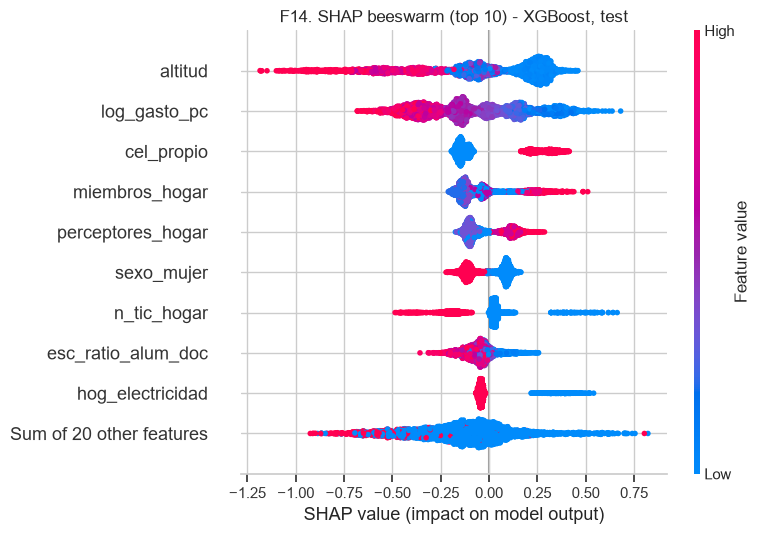


Top variables numéricas: ['altitud', 'log_gasto_pc', 'cel_propio', 'miembros_hogar', 'perceptores_hogar', 'sexo_mujer']


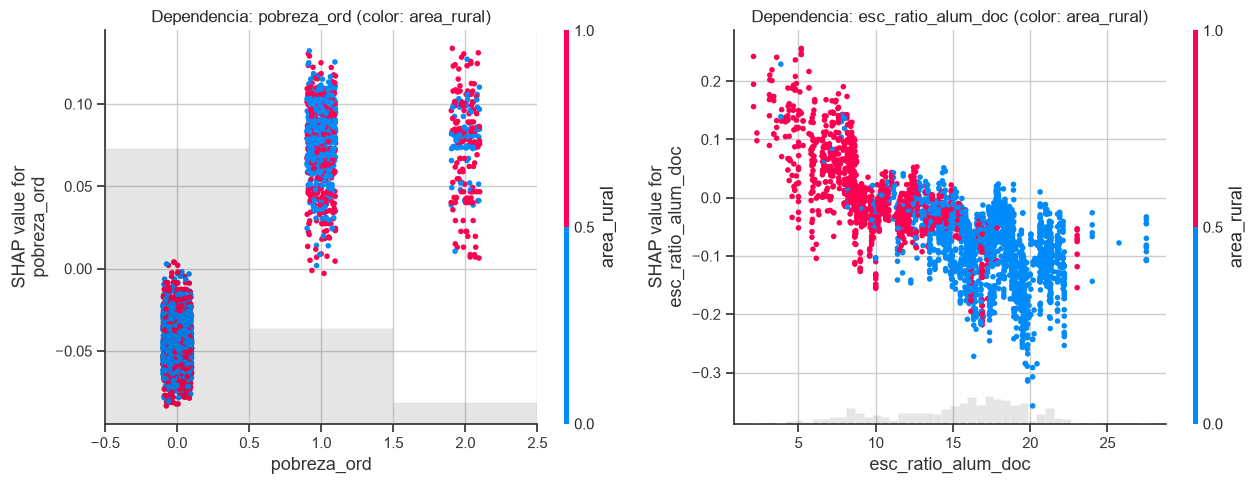


Caso alto riesgo (TP): 3788 | p cruda = 0.892
Caso bajo riesgo (TN): 2972 | p cruda = 0.062


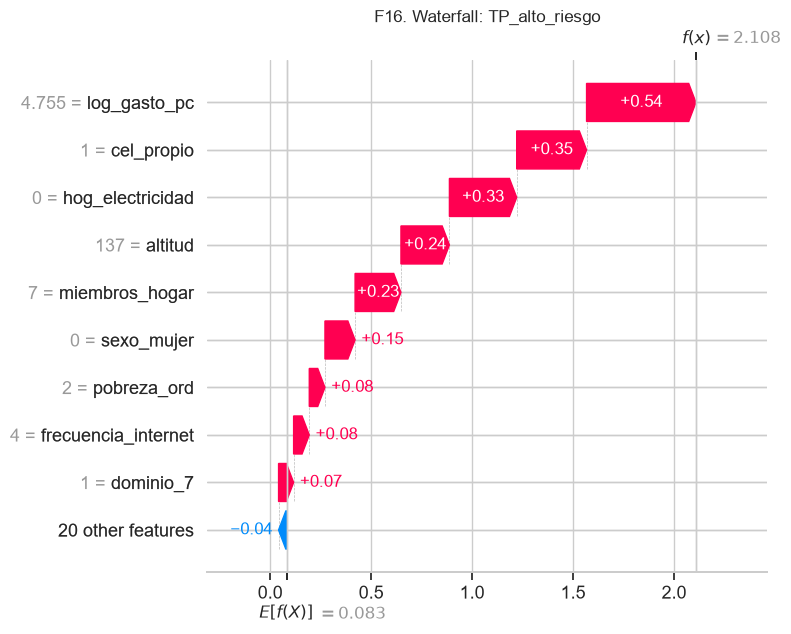

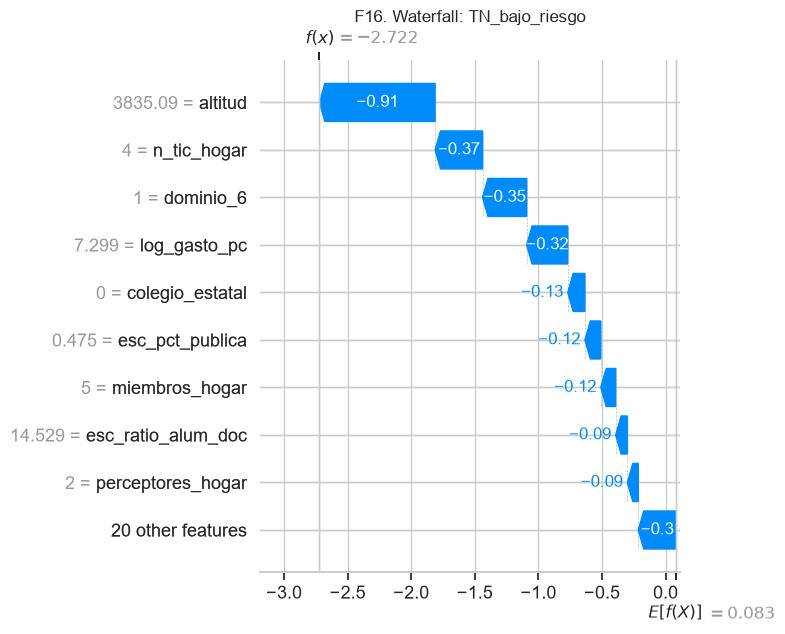


Dirección (corr. valor-SHAP, o diferencia en binarias): {'altitud': np.float64(-0.89), 'log_gasto_pc': np.float64(-0.92), 'cel_propio': np.float32(0.418), 'miembros_hogar': np.float64(0.61), 'perceptores_hogar': np.float64(0.78), 'sexo_mujer': np.float32(-0.194), 'n_tic_hogar': np.float64(-0.97), 'esc_ratio_alum_doc': np.float64(-0.7), 'hog_electricidad': np.float32(-0.402), 'dominio_6': np.float32(-0.396)}


In [20]:
import shap, joblib
from pathlib import Path
import pandas as pd, numpy as np, json, warnings
warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt

SEED = 42
PROC = Path('.').resolve() / 'processed'; EDA = PROC / 'eda'

m   = pd.read_parquet(PROC / 'dataset_enaho_escale_2025.parquet')
sp  = pd.read_parquet(PROC / 'split_train_test.parquet')
art = joblib.load(PROC / 'modelo_final.joblib')
pipe, num, cat = art['modelo'], art['num'], art['cat']
pt = pd.read_parquet(PROC / 'test_predicciones.parquet')

v  = m[m['es_valido_obj'] == 1].reset_index(drop=True)
te = np.where(sp['split'] == 'test')[0]
Xte = v.iloc[te][num + cat].copy().reset_index(drop=True); Xte[cat] = Xte[cat].astype(str)
assert (v.iloc[te]['numper'].values == pt['numper'].values).all()

# Matriz transformada y nombres de columnas legibles
prep, clf = pipe.named_steps['prep'], pipe.named_steps['clf']
Xt = prep.transform(Xte)
nombres = [n.split('__', 1)[1] for n in prep.get_feature_names_out()]
Xdf = pd.DataFrame(Xt, columns=nombres)

# SHAP (TreeExplainer, log-odds)
expl = shap.TreeExplainer(clf)
sv = expl(Xdf)
print("Valor base (log-odds):", np.round(sv.base_values[0], 3), "| n explicados:", len(Xdf))

# Importancia global
imp = pd.Series(np.abs(sv.values).mean(0), index=nombres).sort_values(ascending=False)
print("\nTop 15 |SHAP| medio:\n", imp.head(15).round(4).to_string())
imp.to_csv(EDA / 'T13_shap_importancia.csv')

# F14: beeswarm top 10
plt.figure()
shap.plots.beeswarm(sv, max_display=10, show=False)
plt.title('F14. SHAP beeswarm (top 10) - XGBoost, test')
plt.tight_layout(); plt.savefig(EDA / 'F14_shap_beeswarm.png', dpi=150, bbox_inches='tight'); plt.show()

# F15: dependence plots (variable principal + interacción automática)
top = [c for c in imp.index if c in num][:6]
print("\nTop variables numéricas:", top)
pares = [('pobreza_ord', 'area_rural'), ('esc_ratio_alum_doc', 'area_rural')]
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, (x, c) in zip(ax, pares):
    shap.plots.scatter(sv[:, x], color=sv[:, c], ax=a, show=False)
    a.set_title(f'Dependencia: {x} (color: {c})')
plt.tight_layout(); plt.savefig(EDA / 'F15_shap_dependence.png', dpi=150, bbox_inches='tight'); plt.show()

# F16: waterfall - alto riesgo bien clasificado (TP) y bajo riesgo bien clasificado (TN)
y = pt['y'].values; p = pt['p_xgb'].values
i_tp = int(np.where((y == 1) & (pt['pred'].values == 1))[0][np.argmax(p[(y == 1) & (pt['pred'].values == 1)])])
i_tn = int(np.where((y == 0) & (pt['pred'].values == 0))[0][np.argmin(p[(y == 0) & (pt['pred'].values == 0)])])
print("\nCaso alto riesgo (TP):", i_tp, "| p cruda =", round(p[i_tp], 3))
print("Caso bajo riesgo (TN):", i_tn, "| p cruda =", round(p[i_tn], 3))
for nombre, i in [('TP_alto_riesgo', i_tp), ('TN_bajo_riesgo', i_tn)]:
    plt.figure()
    shap.plots.waterfall(sv[i], max_display=10, show=False)
    plt.title(f'F16. Waterfall: {nombre}')
    plt.tight_layout(); plt.savefig(EDA / f'F16_waterfall_{nombre}.png', dpi=150, bbox_inches='tight'); plt.show()

# Resumen de dirección del efecto (media de SHAP según valor alto/bajo)
dir_ = {}
for c in imp.index[:10]:
    x = Xdf[c].values; s = sv.values[:, nombres.index(c)]
    if np.unique(x).size > 2:
        dir_[c] = round(np.corrcoef(x, s)[0, 1], 2)
    else:
        dir_[c] = round(s[x == x.max()].mean() - s[x == x.min()].mean(), 3)
print("\nDirección (corr. valor-SHAP, o diferencia en binarias):", dir_)

cel_propio por edad:
 {6.0: 0.03, 7.0: 0.02, 8.0: 0.04, 9.0: 0.04, 10.0: 0.07, 11.0: 0.1, 12.0: 0.19, 13.0: 0.33, 14.0: 0.47, 15.0: 0.6, 16.0: 0.7, 17.0: 0.77}

frecuencia_internet media por edad:
 {6.0: 1.59, 7.0: 1.7, 8.0: 2.02, 9.0: 2.19, 10.0: 2.43, 11.0: 2.67, 12.0: 2.95, 13.0: 3.26, 14.0: 3.39, 15.0: 3.58, 16.0: 3.64, 17.0: 3.73}

Spearman con edad: {'cel_propio': np.float64(0.55), 'frecuencia_internet': np.float64(0.4), 'n_tic_hogar': np.float64(0.0), 'miembros_hogar': np.float64(-0.04), 'perceptores_hogar': np.float64(0.12), 'sexo_mujer': np.float64(-0.01), 'altitud': np.float64(0.02)}

Rezago por dominio:
                        n  casos  rezago_pct  altitud_media
region                                                    
Costa centro        1796   82.0        4.57         276.65
Costa norte         3009  125.0        4.15         116.90
Costa sur           1054   29.0        2.75         721.36
Lima Metropolitana  2062   84.0        4.07         192.19
Selva               536

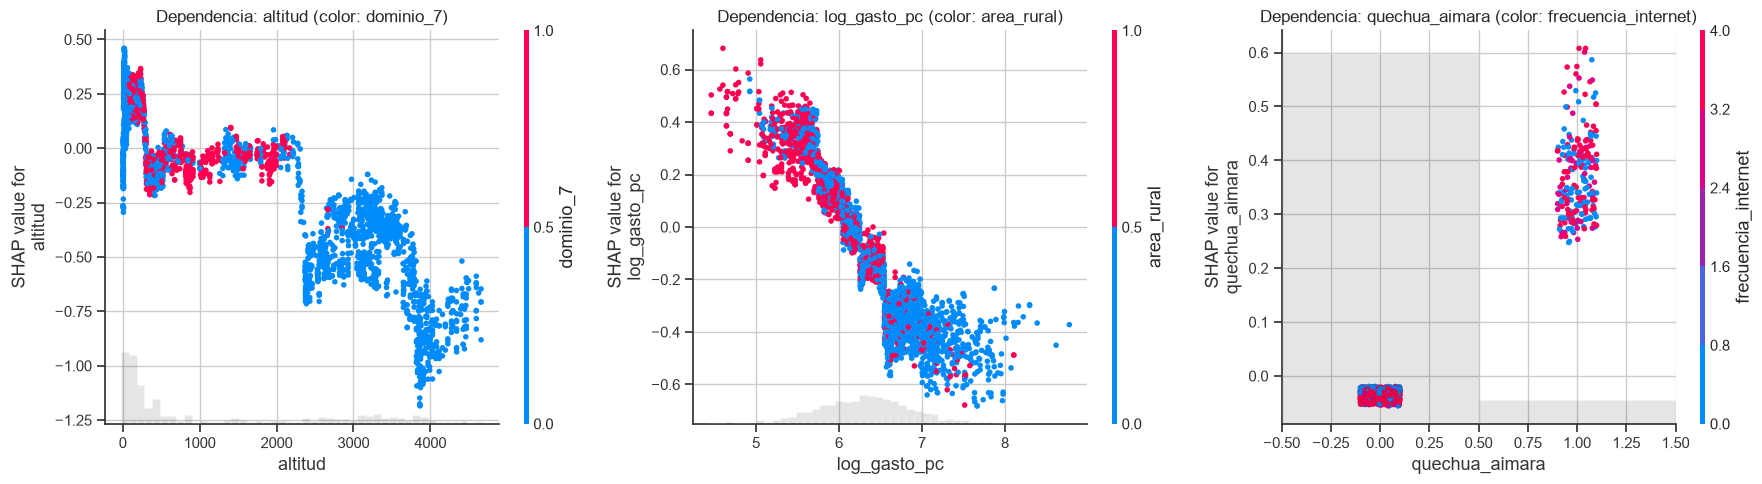


SHAP medio de quechua_aimara según uso de internet:
                              count   mean
quechua_aimara sin_internet              
0.0            False          2716 -0.034
               True            930 -0.031
1.0            False           140  0.380
               True             94  0.363
TP alto riesgo: p cruda = 0.892 | p recalibrada = 0.282
TN bajo riesgo: p cruda = 0.062 | p recalibrada = 0.004


In [21]:
import shap, joblib
from pathlib import Path
import pandas as pd, numpy as np, warnings
warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import roc_auc_score, average_precision_score

SEED = 42
PROC = Path('.').resolve() / 'processed'; EDA = PROC / 'eda'

m   = pd.read_parquet(PROC / 'dataset_enaho_escale_2025.parquet')
sp  = pd.read_parquet(PROC / 'split_train_test.parquet')
art = joblib.load(PROC / 'modelo_final.joblib')
pipe, num, cat = art['modelo'], art['num'], art['cat']
pt  = pd.read_parquet(PROC / 'test_predicciones.parquet')

v = m[m['es_valido_obj'] == 1].reset_index(drop=True)
assert (v['numper'].values == sp['numper'].values).all()
tr, te = np.where(sp['split'] == 'train')[0], np.where(sp['split'] == 'test')[0]
X = v[num + cat].copy(); X[cat] = X[cat].astype(str)
y = v['rezago'].astype(int); g = v['conglome_25']

# ---------- A) ¿Qué variables delatan la edad? (solo diagnóstico) ----------
print("cel_propio por edad:\n", v.groupby('edad')['cel_propio'].mean().round(2).to_dict())
print("\nfrecuencia_internet media por edad:\n", v.groupby('edad')['frecuencia_internet'].mean().round(2).to_dict())
cand = ['cel_propio', 'frecuencia_internet', 'n_tic_hogar', 'miembros_hogar', 'perceptores_hogar', 'sexo_mujer', 'altitud']
print("\nSpearman con edad:", {c: round(v[c].corr(v['edad'], method='spearman'), 2) for c in cand})

# Altitud: ¿es un marcador de región? (codificación estándar ENAHO: 1-3 costa, 4-6 sierra, 7 selva, 8 Lima; verificar en el diccionario)
nom = {'1': 'Costa norte', '2': 'Costa centro', '3': 'Costa sur', '4': 'Sierra norte',
       '5': 'Sierra centro', '6': 'Sierra sur', '7': 'Selva', '8': 'Lima Metropolitana'}
reg = v.assign(region=v['dominio'].astype(str).map(nom)).groupby('region').agg(
        n=('rezago', 'size'), casos=('rezago', 'sum'), rezago_pct=('rezago', lambda s: 100 * s.mean()),
        altitud_media=('altitud', 'mean')).round(2)
print("\nRezago por dominio:\n", reg)

# ---------- B) Sensibilidad: CV sobre train, con y sin las variables sospechosas ----------
Xtr, ytr, gtr = X.iloc[tr].reset_index(drop=True), y.iloc[tr].reset_index(drop=True), g.iloc[tr].reset_index(drop=True)

def armar(cols_num):
    prep = ColumnTransformer([
        ('num', SimpleImputer(strategy='median'), cols_num),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                          ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat)])
    return Pipeline([('prep', prep), ('clf', clone(pipe.named_steps['clf']))])

escenarios = {
    'Completo (modelo final)': num,
    'Sin cel_propio': [c for c in num if c != 'cel_propio'],
    'Sin cel_propio ni frecuencia_internet': [c for c in num if c not in ('cel_propio', 'frecuencia_internet')],
}
gkf, filas = GroupKFold(n_splits=5), []
for nombre, cols in escenarios.items():
    rocs, aps = [], []
    for a, b in gkf.split(Xtr, ytr, gtr):
        p = armar(cols).fit(Xtr.iloc[a], ytr.iloc[a]).predict_proba(Xtr.iloc[b])[:, 1]
        rocs.append(roc_auc_score(ytr.iloc[b], p)); aps.append(average_precision_score(ytr.iloc[b], p))
    filas.append({'escenario': nombre, 'ROC-AUC CV': f"{np.mean(rocs):.3f} ± {np.std(rocs):.3f}",
                  'PR-AUC CV': f"{np.mean(aps):.3f} ± {np.std(aps):.3f}"})
sens = pd.DataFrame(filas)
print("\nSensibilidad (CV sobre train):\n", sens.to_string(index=False))
sens.to_csv(EDA / 'T14_sensibilidad_proxies.csv', index=False)

# ---------- C) SHAP: dependence plots más informativos ----------
prep, clf = pipe.named_steps['prep'], pipe.named_steps['clf']
Xte = X.iloc[te].reset_index(drop=True)
nombres = [n.split('__', 1)[1] for n in prep.get_feature_names_out()]
Xdf = pd.DataFrame(prep.transform(Xte), columns=nombres)
sv = shap.TreeExplainer(clf)(Xdf)

pares = [('altitud', 'dominio_7'), ('log_gasto_pc', 'area_rural'), ('quechua_aimara', 'frecuencia_internet')]
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, (xv, cv) in zip(ax, pares):
    shap.plots.scatter(sv[:, xv], color=sv[:, cv], ax=a, show=False)
    a.set_title(f'Dependencia: {xv} (color: {cv})')
plt.tight_layout(); plt.savefig(EDA / 'F17_shap_dependence_v2.png', dpi=150, bbox_inches='tight'); plt.show()

# Interacción quechua/aimara × uso de internet (el ejemplo del PDF), en números
q, f = Xdf['quechua_aimara'].values, Xdf['frecuencia_internet'].values
s = sv.values[:, nombres.index('quechua_aimara')]
print("\nSHAP medio de quechua_aimara según uso de internet:\n",
      pd.DataFrame({'quechua_aimara': q, 'sin_internet': f == 0, 'shap': s})
        .groupby(['quechua_aimara', 'sin_internet'])['shap'].agg(['count', 'mean']).round(3))

# ---------- D) Probabilidad recalibrada de los dos casos de los waterfall ----------
for nombre, i in [('TP alto riesgo', 3788), ('TN bajo riesgo', 2972)]:
    print(f"{nombre}: p cruda = {pt.loc[i, 'p_xgb']:.3f} | p recalibrada = {pt.loc[i, 'p_xgb_cal']:.3f}")

Predictores finales: 16 num + 2 cat

TEST modelo final (sin proxies de edad), n=3880, positivos=151
  ROC-AUC   0.674 [0.622-0.722]
  PR-AUC    0.092 [0.067-0.128]
  F1 macro  0.546 [0.523-0.569]
Umbral OOF 0.633 | TN=3364 FP=365 FN=107 TP=44 | precisión 0.108 | recall 0.291
Brier recalibrado: 0.0367 | prevalencia constante: 0.0374
Top 10%: captura 28.5% | lift 2.85x
Top 20%: captura 41.7% | lift 2.09x
Top 30%: captura 55.6% | lift 1.85x

Top 12 |SHAP| medio (modelo final):
 altitud               0.2792
log_gasto_pc          0.2205
perceptores_hogar     0.1432
miembros_hogar        0.1340
sexo_mujer            0.1164
n_tic_hogar           0.0861
dominio_6             0.0786
esc_n_ie              0.0774
hog_electricidad      0.0754
pobreza_ord           0.0712
esc_ratio_alum_doc    0.0654
quechua_aimara        0.0492


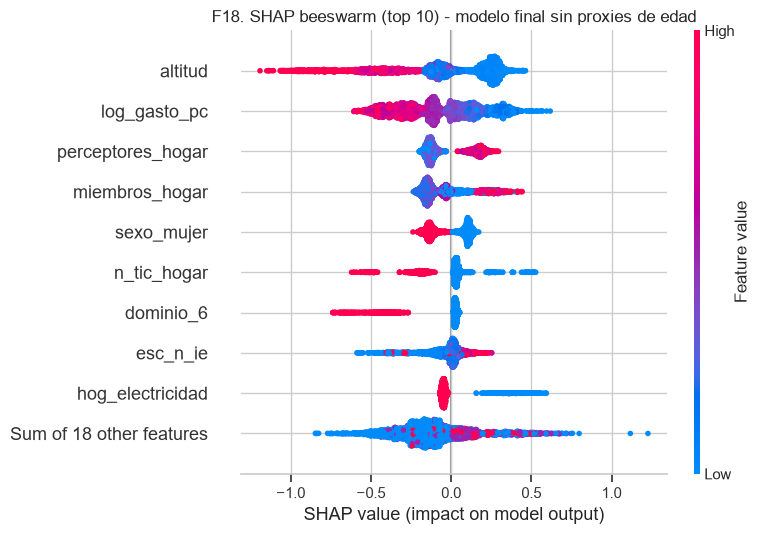


TP: 3647 (p cal = 0.191) | TN: 2972 (p cal = 0.0037)


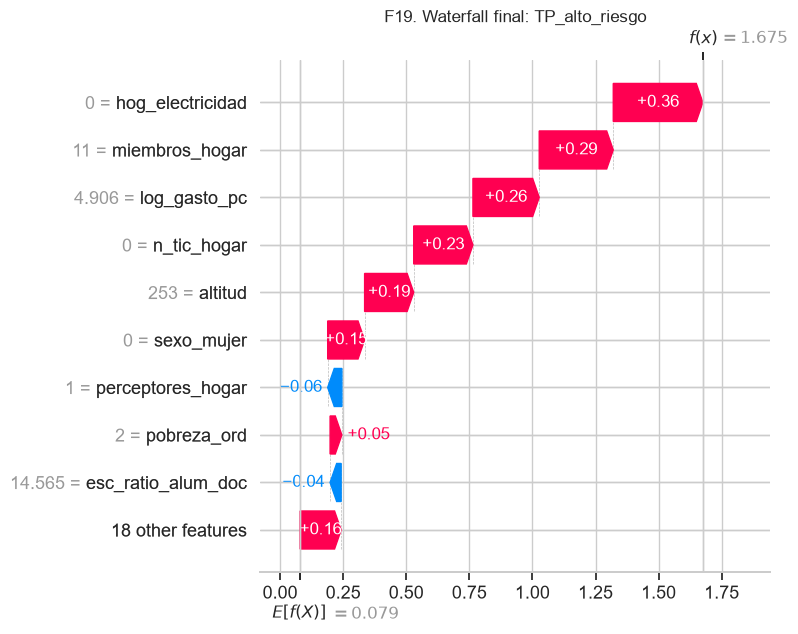

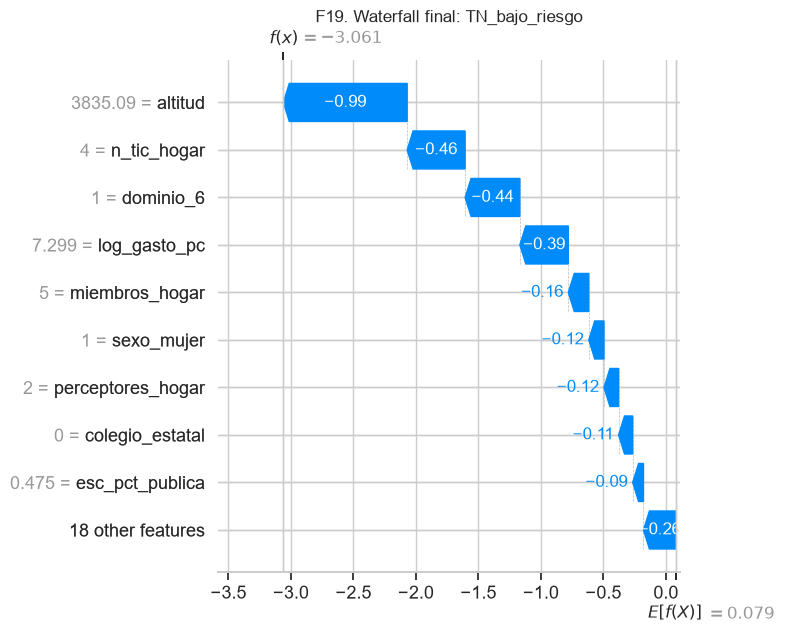


Guardado modelo_final_sin_proxies.joblib


In [22]:
import shap, joblib
from pathlib import Path
import pandas as pd, numpy as np, warnings
warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score,
                             confusion_matrix, precision_score, recall_score, brier_score_loss)

SEED = 42
PROC = Path('.').resolve() / 'processed'; EDA = PROC / 'eda'

m   = pd.read_parquet(PROC / 'dataset_enaho_escale_2025.parquet')
sp  = pd.read_parquet(PROC / 'split_train_test.parquet')
art = joblib.load(PROC / 'modelo_final.joblib')
pipe, num_old, cat = art['modelo'], art['num'], art['cat']

num = [c for c in num_old if c not in ('cel_propio', 'frecuencia_internet')]
assert not ({'cel_propio', 'frecuencia_internet', 'edad', 'grado', 'anios_retraso'} & set(num + cat))
print("Predictores finales:", len(num), "num +", len(cat), "cat")

v = m[m['es_valido_obj'] == 1].reset_index(drop=True)
assert (v['numper'].values == sp['numper'].values).all()
tr, te = np.where(sp['split'] == 'train')[0], np.where(sp['split'] == 'test')[0]
X = v[num + cat].copy(); X[cat] = X[cat].astype(str)
y = v['rezago'].astype(int); g = v['conglome_25']
Xtr, ytr, gtr = X.iloc[tr].reset_index(drop=True), y.iloc[tr].reset_index(drop=True), g.iloc[tr].reset_index(drop=True)
Xte, yte = X.iloc[te].reset_index(drop=True), y.iloc[te].reset_index(drop=True)

def armar():
    prep = ColumnTransformer([
        ('num', SimpleImputer(strategy='median'), num),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                          ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat)])
    return Pipeline([('prep', prep), ('clf', clone(pipe.named_steps['clf']))])

# OOF en train: umbral y recalibración (solo con train)
def mejor_umbral(yt, p):
    ths = np.unique(np.quantile(p, np.linspace(0.50, 0.995, 150)))
    return ths[int(np.argmax([f1_score(yt, (p >= t).astype(int), average='macro') for t in ths]))]
oof = np.zeros(len(Xtr))
for a, b in GroupKFold(n_splits=5).split(Xtr, ytr, gtr):
    oof[b] = armar().fit(Xtr.iloc[a], ytr.iloc[a]).predict_proba(Xtr.iloc[b])[:, 1]
th = mejor_umbral(ytr, oof)

final = armar().fit(Xtr, ytr)
p = final.predict_proba(Xte)[:, 1]; pred = (p >= th).astype(int)
lg = lambda q: np.log(np.clip(q, 1e-6, 1 - 1e-6) / (1 - np.clip(q, 1e-6, 1 - 1e-6))).reshape(-1, 1)
platt = LogisticRegression(C=1e6).fit(lg(oof), ytr)
p_cal = platt.predict_proba(lg(p))[:, 1]

# Bootstrap por conglomerado (test)
gte = g.iloc[te].reset_index(drop=True)
rng = np.random.RandomState(SEED)
idx_g = {k: np.array(ix) for k, ix in gte.groupby(gte).groups.items()}
claves = np.array(list(idx_g.keys()))
muestras = [np.concatenate([idx_g[k] for k in rng.choice(claves, len(claves), replace=True)]) for _ in range(1000)]
def met(yt, q):
    pr = (q >= th).astype(int)
    return [roc_auc_score(yt, q), average_precision_score(yt, q), f1_score(yt, pr, average='macro')]
boot = np.array([met(yte.values[i], p[i]) for i in muestras if yte.values[i].sum() > 0])
pt_ = met(yte.values, p); lo, hi = np.quantile(boot, 0.025, 0), np.quantile(boot, 0.975, 0)
print(f"\nTEST modelo final (sin proxies de edad), n={len(yte)}, positivos={yte.sum()}")
for n_, a_, l_, h_ in zip(['ROC-AUC', 'PR-AUC', 'F1 macro'], pt_, lo, hi):
    print(f"  {n_:9s} {a_:.3f} [{l_:.3f}-{h_:.3f}]")
tn, fp, fn, tp = confusion_matrix(yte, pred).ravel()
print(f"Umbral OOF {th:.3f} | TN={tn} FP={fp} FN={fn} TP={tp} | precisión {tp/(tp+fp):.3f} | recall {tp/(tp+fn):.3f}")
print(f"Brier recalibrado: {brier_score_loss(yte, p_cal):.4f} | prevalencia constante: {brier_score_loss(yte, np.full(len(yte), ytr.mean())):.4f}")
orden = np.argsort(-p)
for q in (0.10, 0.20, 0.30):
    top = yte.values[orden[:int(len(orden) * q)]]
    print(f"Top {q:.0%}: captura {top.sum()/yte.sum():.1%} | lift {top.mean()/yte.mean():.2f}x")

# SHAP del modelo final
prep, clf = final.named_steps['prep'], final.named_steps['clf']
nombres = [n.split('__', 1)[1] for n in prep.get_feature_names_out()]
Xdf = pd.DataFrame(prep.transform(Xte), columns=nombres)
sv = shap.TreeExplainer(clf)(Xdf)
imp = pd.Series(np.abs(sv.values).mean(0), index=nombres).sort_values(ascending=False)
print("\nTop 12 |SHAP| medio (modelo final):\n", imp.head(12).round(4).to_string())
imp.to_csv(EDA / 'T15_shap_importancia_final.csv')

plt.figure(); shap.plots.beeswarm(sv, max_display=10, show=False)
plt.title('F18. SHAP beeswarm (top 10) - modelo final sin proxies de edad')
plt.tight_layout(); plt.savefig(EDA / 'F18_shap_beeswarm_final.png', dpi=150, bbox_inches='tight'); plt.show()

# Waterfall: mismo criterio que antes (TP más seguro y TN más seguro) con el modelo final
y_ = yte.values
i_tp = int(np.where((y_ == 1) & (pred == 1))[0][np.argmax(p[(y_ == 1) & (pred == 1)])])
i_tn = int(np.where((y_ == 0) & (pred == 0))[0][np.argmin(p[(y_ == 0) & (pred == 0)])])
print(f"\nTP: {i_tp} (p cal = {p_cal[i_tp]:.3f}) | TN: {i_tn} (p cal = {p_cal[i_tn]:.4f})")
for nombre, i in [('TP_alto_riesgo', i_tp), ('TN_bajo_riesgo', i_tn)]:
    plt.figure(); shap.plots.waterfall(sv[i], max_display=10, show=False)
    plt.title(f'F19. Waterfall final: {nombre}')
    plt.tight_layout(); plt.savefig(EDA / f'F19_waterfall_final_{nombre}.png', dpi=150, bbox_inches='tight'); plt.show()

joblib.dump({'modelo': final, 'umbral': th, 'num': num, 'cat': cat}, PROC / 'modelo_final_sin_proxies.joblib')
pd.DataFrame({'numper': v.iloc[te]['numper'].values, 'y': y_, 'p': p, 'p_cal': p_cal, 'pred': pred}) \
  .to_parquet(PROC / 'test_predicciones_final.parquet', index=False)
print("\nGuardado modelo_final_sin_proxies.joblib")

                  modelo  umbral (OOF)             ROC-AUC              PR-AUC            F1 macro           Precisión              Recall Captura top 10% Captura top 20%
Baseline: Reg. logística         0.696 0.664 [0.606-0.715] 0.099 [0.070-0.134] 0.554 [0.526-0.580] 0.121 [0.078-0.160] 0.232 [0.147-0.321]           30.5%           42.4%
                 XGBoost         0.633 0.674 [0.622-0.722] 0.092 [0.067-0.128] 0.546 [0.523-0.569] 0.108 [0.076-0.141] 0.291 [0.201-0.386]           28.5%           41.7%
                LightGBM         0.660 0.668 [0.615-0.716] 0.098 [0.071-0.132] 0.542 [0.518-0.562] 0.104 [0.068-0.136] 0.192 [0.112-0.274]           27.2%           43.7%
           Random Forest         0.608 0.664 [0.609-0.711] 0.103 [0.073-0.144] 0.564 [0.535-0.590] 0.139 [0.092-0.185] 0.225 [0.138-0.312]           34.4%           41.7%
Control: XGBoost debe reproducir ROC-AUC 0.674 y PR-AUC 0.092 -> 0.674 0.092


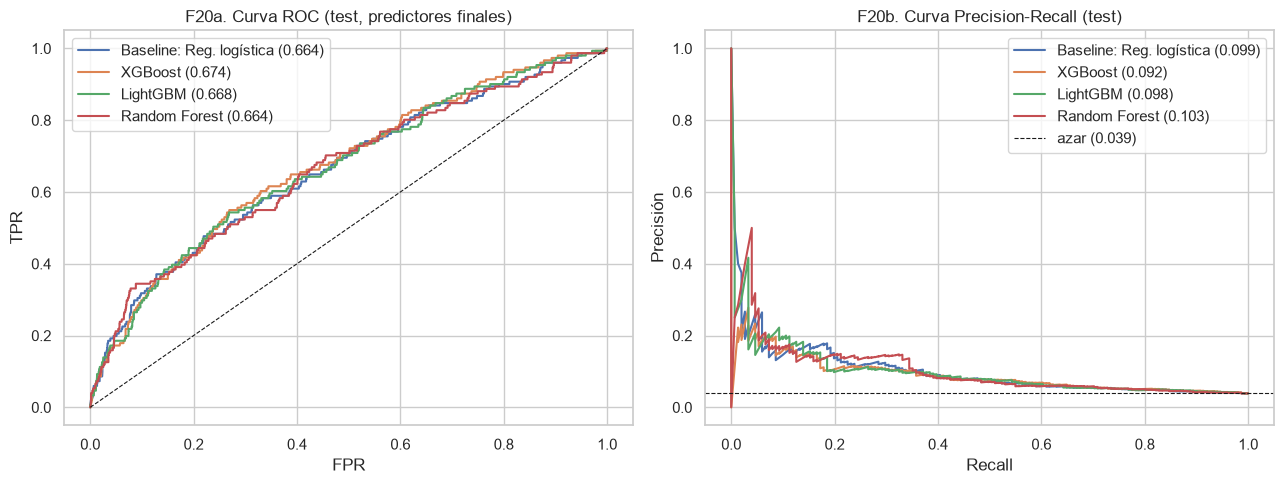

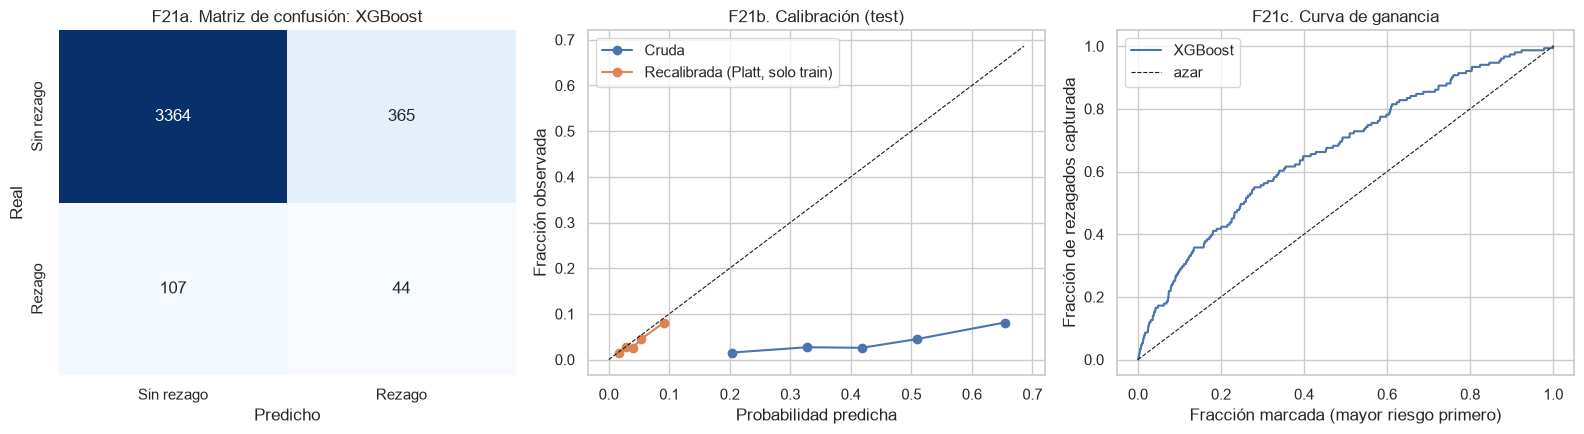


XGBoost: TN=3364 FP=365 FN=107 TP=44 | Brier cal 0.0367

Perfil de aciertos y errores:
 grupo                  TP      FP      FN       TN
edad                13.57   11.18   13.98    11.55
secundaria           0.48    0.43    0.64     0.49
area_rural           0.61    0.51    0.28     0.32
pobreza_ord          1.09    0.91    0.26     0.29
quechua_aimara       0.05    0.09    0.07     0.06
otra_lengua          0.16    0.08    0.00     0.00
colegio_estatal      0.98    0.96    0.92     0.83
log_gasto_pc         5.63    5.77    6.36     6.39
miembros_hogar       6.64    6.48    4.94     4.62
perceptores_hogar    2.57    2.68    2.40     2.24
altitud            510.28  534.62  995.61  1309.25
sexo_mujer           0.20    0.33    0.50     0.50
n                   44.00  365.00  107.00  3364.00
Recall por área (0 urbano, 1 rural): {0: 0.181, 1: 0.474}
Recall por nivel (0 primaria, 1 secundaria): {0: 0.377, 1: 0.233}


In [23]:
from pathlib import Path
import pandas as pd, numpy as np, warnings, joblib
warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.base import clone
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import calibration_curve
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, confusion_matrix,
                             roc_curve, precision_recall_curve, precision_score, recall_score, brier_score_loss)

SEED = 42
PROC = Path('.').resolve() / 'processed'; EDA = PROC / 'eda'
sns.set_theme(style='whitegrid')
def guardar(n):
    plt.tight_layout(); plt.savefig(EDA / f'{n}.png', dpi=150, bbox_inches='tight'); plt.show()

m   = pd.read_parquet(PROC / 'dataset_enaho_escale_2025.parquet')
sp  = pd.read_parquet(PROC / 'split_train_test.parquet')
art = joblib.load(PROC / 'modelo_final_sin_proxies.joblib'); num, cat = art['num'], art['cat']
mejores = joblib.load(PROC / 'modelos_ajustados.joblib')

v = m[m['es_valido_obj'] == 1].reset_index(drop=True)
assert (v['numper'].values == sp['numper'].values).all()
assert not ({'cel_propio', 'frecuencia_internet', 'edad', 'grado', 'anios_retraso'} & set(num + cat))
tr, te = np.where(sp['split'] == 'train')[0], np.where(sp['split'] == 'test')[0]
X = v[num + cat].copy(); X[cat] = X[cat].astype(str); y = v['rezago'].astype(int); g = v['conglome_25']
Xtr, ytr, gtr = X.iloc[tr].reset_index(drop=True), y.iloc[tr].reset_index(drop=True), g.iloc[tr].reset_index(drop=True)
Xte, yte, gte = X.iloc[te].reset_index(drop=True), y.iloc[te].reset_index(drop=True), g.iloc[te].reset_index(drop=True)
vte = v.iloc[te].reset_index(drop=True)

def armar(clf, escalar):
    pasos = [('imp', SimpleImputer(strategy='median'))] + ([('sc', StandardScaler())] if escalar else [])
    prep = ColumnTransformer([('num', Pipeline(pasos), num),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                          ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat)])
    return Pipeline([('prep', prep), ('clf', clone(clf))])

modelos = {
 'Baseline: Reg. logística': armar(LogisticRegression(C=0.1, class_weight='balanced', max_iter=2000, random_state=SEED), True),
 'XGBoost': armar(mejores['XGBoost'].named_steps['clf'], False),
 'LightGBM': armar(mejores['LightGBM'].named_steps['clf'], False),
 'Random Forest': armar(mejores['Random Forest'].named_steps['clf'], False)}
GANADOR = 'XGBoost'

def mejor_umbral(yt, p):
    ths = np.unique(np.quantile(p, np.linspace(0.50, 0.995, 150)))
    return ths[int(np.argmax([f1_score(yt, (p >= t).astype(int), average='macro') for t in ths]))]

oof, p_te, umbral = {}, {}, {}
for n, pipe in modelos.items():
    o = np.zeros(len(Xtr))
    for a, b in GroupKFold(n_splits=5).split(Xtr, ytr, gtr):
        o[b] = clone(pipe).fit(Xtr.iloc[a], ytr.iloc[a]).predict_proba(Xtr.iloc[b])[:, 1]
    oof[n] = o; umbral[n] = mejor_umbral(ytr, o)
    p_te[n] = clone(pipe).fit(Xtr, ytr).predict_proba(Xte)[:, 1]

# Bootstrap por conglomerado
rng = np.random.RandomState(SEED)
idx_g = {k: np.array(ix) for k, ix in gte.groupby(gte).groups.items()}; claves = np.array(list(idx_g))
muestras = [np.concatenate([idx_g[k] for k in rng.choice(claves, len(claves), replace=True)]) for _ in range(1000)]
def met(yt, p, th):
    pr = (p >= th).astype(int)
    return {'ROC-AUC': roc_auc_score(yt, p), 'PR-AUC': average_precision_score(yt, p), 'F1 macro': f1_score(yt, pr, average='macro'),
            'Precisión': precision_score(yt, pr, zero_division=0), 'Recall': recall_score(yt, pr)}
filas = []
for n in modelos:
    pt = met(yte.values, p_te[n], umbral[n])
    bt = pd.DataFrame([met(yte.values[i], p_te[n][i], umbral[n]) for i in muestras if yte.values[i].sum() > 0])
    lo, hi = bt.quantile(.025), bt.quantile(.975)
    f = {'modelo': n, 'umbral (OOF)': round(umbral[n], 3)}
    for k in pt: f[k] = f"{pt[k]:.3f} [{lo[k]:.3f}-{hi[k]:.3f}]"
    o = np.argsort(-p_te[n])
    for q in (0.10, 0.20):
        top = yte.values[o[:int(len(o) * q)]]; f[f'Captura top {q:.0%}'] = f"{top.sum() / yte.sum():.1%}"
    filas.append(f)
res = pd.DataFrame(filas); print(res.to_string(index=False)); res.to_csv(EDA / 'T16_test_modelos_final.csv', index=False)
print("Control: XGBoost debe reproducir ROC-AUC 0.674 y PR-AUC 0.092 ->",
      round(roc_auc_score(yte, p_te['XGBoost']), 3), round(average_precision_score(yte, p_te['XGBoost']), 3))

# F20: ROC y PR
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for n in modelos:
    f_, t_, _ = roc_curve(yte, p_te[n]); ax[0].plot(f_, t_, label=f"{n} ({roc_auc_score(yte, p_te[n]):.3f})")
    pr, rc, _ = precision_recall_curve(yte, p_te[n]); ax[1].plot(rc, pr, label=f"{n} ({average_precision_score(yte, p_te[n]):.3f})")
ax[0].plot([0, 1], [0, 1], 'k--', lw=.8); ax[0].set_title('F20a. Curva ROC (test, predictores finales)'); ax[0].set_xlabel('FPR'); ax[0].set_ylabel('TPR'); ax[0].legend()
ax[1].axhline(yte.mean(), color='k', ls='--', lw=.8, label=f'azar ({yte.mean():.3f})')
ax[1].set_title('F20b. Curva Precision-Recall (test)'); ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precisión'); ax[1].legend()
guardar('F20_roc_pr_final')

# F21: confusión, calibración, ganancia (ganador)
pg, th = p_te[GANADOR], umbral[GANADOR]; pred = (pg >= th).astype(int)
cm = confusion_matrix(yte, pred)
lg = lambda q: np.log(np.clip(q, 1e-6, 1 - 1e-6) / (1 - np.clip(q, 1e-6, 1 - 1e-6))).reshape(-1, 1)
pg_cal = LogisticRegression(C=1e6).fit(lg(oof[GANADOR]), ytr).predict_proba(lg(pg))[:, 1]
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax[0], xticklabels=['Sin rezago', 'Rezago'], yticklabels=['Sin rezago', 'Rezago'])
ax[0].set_title(f'F21a. Matriz de confusión: {GANADOR}'); ax[0].set_xlabel('Predicho'); ax[0].set_ylabel('Real')
for et, pp in [('Cruda', pg), ('Recalibrada (Platt, solo train)', pg_cal)]:
    fr, mp = calibration_curve(yte, pp, n_bins=5, strategy='quantile'); ax[1].plot(mp, fr, marker='o', label=et)
mx = max(ax[1].get_xlim()[1], ax[1].get_ylim()[1]); ax[1].plot([0, mx], [0, mx], 'k--', lw=.8)
ax[1].set_title('F21b. Calibración (test)'); ax[1].set_xlabel('Probabilidad predicha'); ax[1].set_ylabel('Fracción observada'); ax[1].legend()
o = np.argsort(-pg); ax[2].plot(np.arange(1, len(o) + 1) / len(o), np.cumsum(yte.values[o]) / yte.sum(), label=GANADOR)
ax[2].plot([0, 1], [0, 1], 'k--', lw=.8, label='azar'); ax[2].set_title('F21c. Curva de ganancia')
ax[2].set_xlabel('Fracción marcada (mayor riesgo primero)'); ax[2].set_ylabel('Fracción de rezagados capturada'); ax[2].legend()
guardar('F21_confusion_calibracion_ganancia')
tn, fp, fn, tp = cm.ravel(); print(f"\n{GANADOR}: TN={tn} FP={fp} FN={fn} TP={tp} | Brier cal {brier_score_loss(yte, pg_cal):.4f}")

# Análisis de errores
vte['secundaria'] = (vte['p308a_25'] == 3).astype(int)
vte['grupo'] = np.select([(pred == 1) & (yte == 1), (pred == 1) & (yte == 0), (pred == 0) & (yte == 1)], ['TP', 'FP', 'FN'], default='TN')
cols = ['edad', 'secundaria', 'area_rural', 'pobreza_ord', 'quechua_aimara', 'otra_lengua', 'colegio_estatal',
        'log_gasto_pc', 'miembros_hogar', 'perceptores_hogar', 'altitud', 'sexo_mujer']
tab = vte.groupby('grupo')[cols].mean().T[['TP', 'FP', 'FN', 'TN']].round(2)
tab.loc['n'] = vte['grupo'].value_counts().reindex(['TP', 'FP', 'FN', 'TN']).values
print("\nPerfil de aciertos y errores:\n", tab.to_string()); tab.to_csv(EDA / 'T17_errores_final.csv')
pos = vte.assign(pred=pred)[vte['rezago'] == 1]
print("Recall por área (0 urbano, 1 rural):", pos.groupby('area_rural')['pred'].mean().round(3).to_dict())
print("Recall por nivel (0 primaria, 1 secundaria):", pos.groupby('secundaria')['pred'].mean().round(3).to_dict())

pd.DataFrame({'numper': vte['numper'], 'y': yte, **{f'p_{k}': p_te[k] for k in p_te}}).to_parquet(PROC / 'test_predicciones_4modelos.parquet', index=False)

In [24]:
from pathlib import Path
import shutil, subprocess, sys
import matplotlib.pyplot as plt

BASE = Path('.').resolve()
PROC = BASE / 'processed'; EDA = PROC / 'eda'
REPO = BASE / 'entrega'
for d in ['data/raw', 'data/processed', 'notebooks', 'src', 'reports/figures', 'reports/tables']:
    (REPO / d).mkdir(parents=True, exist_ok=True)

# ---------- 1) Paneles para el informe ----------
def panel(nombres, salida, ancho=12, horizontal=False):
    imgs = [plt.imread(EDA / f'{n}.png') for n in nombres]
    if horizontal:
        fig, axs = plt.subplots(1, len(imgs), figsize=(ancho, ancho / len(imgs) * imgs[0].shape[0] / imgs[0].shape[1]))
    else:
        alturas = [ancho * i.shape[0] / i.shape[1] for i in imgs]
        fig, axs = plt.subplots(len(imgs), 1, figsize=(ancho, sum(alturas)),
                                gridspec_kw={'height_ratios': alturas})
    for ax, im in zip(axs, imgs):
        ax.imshow(im); ax.axis('off')
    plt.subplots_adjust(hspace=0.02, wspace=0.02)
    fig.savefig(REPO / 'reports/figures' / f'{salida}.png', dpi=200, bbox_inches='tight'); plt.close(fig)

panel(['F1_objetivo', 'F4_brecha_digital'], 'P1_eda')
panel(['F8_seleccion_k', 'F10_perfil_heatmap'], 'P2_clustering')
panel(['F20_roc_pr_final', 'F21_confusion_calibracion_ganancia'], 'P3_clasificacion')
panel(['F18_shap_beeswarm_final', 'F17_shap_dependence_v2'], 'P4_shap')
panel(['F19_waterfall_final_TP_alto_riesgo', 'F19_waterfall_final_TN_bajo_riesgo'], 'P5_waterfall', ancho=12, horizontal=True)

# ---------- 2) Copia de figuras y tablas individuales (para el anexo) ----------
for f in EDA.glob('*.png'): shutil.copy(f, REPO / 'reports/figures' / f.name)
for f in EDA.glob('*.csv'): shutil.copy(f, REPO / 'reports/tables' / f.name)

# ---------- 3) Datos finales (sin los parquet intermedios ni los CSV panel) ----------
for n in ['dataset_enaho_escale_2025.parquet', 'dataset_enaho_escale_2025.csv',
          'diccionario_variables.csv', 'config_variables.json', 'split_train_test.parquet']:
    shutil.copy(PROC / n, REPO / 'data/processed' / n)

# ---------- 4) requirements.txt y README base ----------
req = subprocess.run([sys.executable, '-m', 'pip', 'freeze'], capture_output=True, text=True).stdout
(REPO / 'requirements.txt').write_text(req)
(REPO / 'data/raw/LEEME.txt').write_text(
    "Colocar aquí (no se incluyen por tamaño):\n"
    "INEI/1041-Modulo1474 (100), 1479 (200), 1475 (300), 1478 (Sumaria): CSV panel 2021-2025, codificación utf-8-sig.\n"
    "MINEDU/00_Padron/Padron.dbf (ESCALE 2025).\n")
print("Entrega armada en:", REPO)
print("Paneles:", sorted(p.name for p in (REPO / 'reports/figures').glob('P*.png')))

Entrega armada en: C:\IA Unidad II\entrega
Paneles: ['P1_eda.png', 'P2_clustering.png', 'P3_clasificacion.png', 'P4_shap.png', 'P5_waterfall.png']


In [25]:
import pandas as pd
from pathlib import Path
PROC = Path('.').resolve() / 'processed'
m = pd.read_parquet(PROC / 'dataset_enaho_escale_2025.parquet')
m['dpto'] = m['ubigeo_25'].str[:2]
tab = pd.crosstab(m['dpto'], m['dominio'])
print(tab.to_string())

dominio     1    2    3    4    5    6     7     8
dpto                                              
01          0    0    0  238    0    0   696     0
02          0  491    0    0  538    0     0     0
03          0    0    0    0    0  568     0     0
04          0    0  301    0    0  685     0     0
05          0    0    0    0  645    0    70     0
06         35    0    0  636    0    0   271     0
07          0    0    0    0    0    0     0   659
08          0    0    0    0    0  582   121     0
09          0    0    0    0  758    0     0     0
10          0    0    0    0  521    0   416     0
11          0  997    0    0    6    0     0     0
12          0    0    0    0  600    0   378     0
13        778    0    0  362    0    0     0     0
14        909    0    0   66    0    0     0     0
15          0  762    0    0  153    0     0  1772
16          0    0    0    0    0    0  1736     0
17          0    0    0    0    0    0   517     0
18          0    0  358    0   